# A shape-conditioned regime brake

A regime brake turns a market regime label into a position size between 0 and 1, once a day. This notebook builds one from the five-minute returns of many assets. Its starting point is a sliced Wasserstein labeler that sorts days into calm, transition and stress, built step by step in the companion notebook [sliced-wasserstein-regimes](https://github.com/FuratGoat/sliced-wasserstein-regimes). The brake adds three things to it.

- Projection directions from a scrambled Sobol sequence, spread evenly over the sphere, instead of random ones.
- A second fingerprint, taken after each asset's volatility is removed inside the window. It sees how the assets move together, and its most concentrated cluster is called the crash shape.
- A release rule. After a stress day the brake normally waits at zero for five sessions. It lets go early when volatility is falling and the market does not have the crash shape.

The idea behind the release is that a shock which fades fast is often a good moment to take risk again, while a crash that comes in legs tends to pause before it falls further. While everything still moves as one block, the brake holds.

The main findings are short.

- Sobol directions cut the error of the sliced distance about threefold at 256 directions when volatility drives the distance, but only by about a fifth when correlations alone change.
- After volatility is removed, the variance of a projection is $\theta^\top R\, \theta$. Its average over directions is always one, and its spread over directions is set by how far the eigenvalues of the correlation matrix are from one. So the shape fingerprint measures co-movement and nothing else.
- On a synthetic market the crash shape flags a planted rise in correlation on almost every day after it and almost never flags a pure volatility shock or a stock–bond flip.
- In a synthetic crash with a bounce between two legs, a plain release rule goes back to half size in the bounce and is caught in the second leg, while the shape condition keeps the brake near zero. After a single volatility shock it lets go nearly as fast as the plain release.
- On real data from 2018 to 2026 the brake spends less than half as many sessions at zero as the labeler with its fixed wait. The weeks after a release were calmer than the weeks after the days it held, but one release in five still came before a fall of more than 5% within ten sessions.
- The weak point is the crash-shape label. Its name comes from comparing cluster averages, which twice differed by less than 0.002, and under other Sobol scrambles its days overlap by only 63% to 91%.

The real market data cannot be redistributed, so the real-data section holds computed results only. Everything else runs from scratch with numpy, pandas, scipy, scikit-learn and matplotlib, in a few minutes, and check cells stop the run if a claim in the text does not hold. The brake's settings were chosen in a backtest of a trading strategy that is not part of this notebook, on data from 2008 to 2025, so every real-data result below is in-sample.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, qmc
from sklearn.cluster import KMeans

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
STATE_NAMES = {0: "calm", 1: "transition", 2: "stress"}
STATE_COLORS = {0: "#8FB8DE", 1: "#F2B447", 2: "#D1495B"}
SIZE_COLORS = {0.0: "#2B2F3A", 0.5: "#9AA3B5", 1.0: "#E9EDF4"}
BRAKE_COLORS = {"wait only": "#7C8392", "plain release": "#F2B447", "shape-conditioned": "#2F5D8A"}
T0 = time.time()
CHECKS = []


def check(name, condition, detail=""):
    # Stop the notebook if a claim made in the text does not hold.
    CHECKS.append(name)
    if not condition:
        raise AssertionError(f"check failed: {name} {detail}")
    print(f"check {len(CHECKS)} passed: {name} {detail}")

## 1. The starting point, a sliced Wasserstein labeler

This section restates the labeler that the brake builds on. The companion notebook derives each step.

#### Scaled returns and the weekly cloud

Let $r_{t,j,i}$ be the log return of asset $i$ in five-minute bar $j$ of session $t$, with 78 bars a session. Each asset is divided by its own typical bar size over the past year, measured up to the day before

$$
\sigma_{t,i}^2 = \frac{1}{252} \sum_{s=t-252}^{t-1} \frac{1}{78} \sum_{j=1}^{78} r_{s,j,i}^2 , \qquad z_{t,j,i} = \frac{r_{t,j,i}}{\sigma_{t,i}}
$$

so a normal bar has $z^2 \approx 1$ for every asset. The last five sessions form a cloud $P_t$ of $5 \times 78 = 390$ points in $\mathbb{R}^d$, and the week's mean scaled variance is

$$
v_t = \frac{1}{390\, d} \sum_{z \in P_t} \lVert z \rVert^2
$$

A value of 1 is a normal week, and 4 means volatility about twice normal.

#### The fingerprint

Fix $L$ unit directions $\theta_1, \dots, \theta_L$ and $Q = 20$ quantile levels $u_k = (k - \tfrac12)/Q$. The fingerprint of a cloud stacks the quantiles of every projection

$$
\phi(P) = \frac{1}{\sqrt{LQ}} \Big( F^{-1}_{\theta_l^\top P}(u_k) \Big)_{l = 1, \dots, L, \; k = 1, \dots, Q}
$$

and the Euclidean distance between two fingerprints is the sliced Wasserstein-2 distance between the clouds, up to the error of using finitely many directions and levels. So k-means on fingerprints is k-means in sliced Wasserstein geometry, and a centroid is the per-direction Wasserstein barycenter of its members.

#### Volatility states and sizes

Every January, k-means with $K = 3$ runs on the fingerprints of the last 504 sessions. The clusters are ranked by the mean of $v$ over their training days and named calm, transition and stress, and each later day gets its nearest centroid. The labeler on its own sizes a position by

$$
m_t = \begin{cases} 1 & s_t = \text{calm} \\ 0.5 & s_t = \text{transition} \\ 0 & s_t = \text{stress or one of the 5 sessions after a stress day} \end{cases}
$$

The five sessions at zero after each stress day are the re-entry wait. They keep the size from flickering at the edge of the stress cluster, but they also keep it at zero after a shock that has already faded. That cost is what the release rule in section 5 targets.

In [2]:
QL = (np.arange(20) + 0.5) / 20   # quantile levels


def scale_streams(X, scale_days=252, min_days=120):
    # X has shape (days, slots, streams). Divide each stream by its trailing sd of intraday returns,
    # measured on earlier days only.
    rv = pd.DataFrame((X**2).sum(axis=1))
    sd = np.sqrt(rv.rolling(scale_days, min_periods=min_days).mean().shift(1).to_numpy() / X.shape[1])
    return X / sd[:, None, :]


def fingerprint(cloud, dirs):
    # Projected quantiles of a point cloud, scaled so that Euclidean distance is the sliced W2 distance.
    return np.quantile(cloud @ dirs.T, QL, axis=0).T.ravel() / np.sqrt(len(dirs) * len(QL))


def daily_variance(Z):
    # Mean squared scaled return of each day over all bars and streams.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # days before the scaling exists are all NaN
        return np.nanmean(Z**2, axis=(1, 2))


def vol_fingerprints(Z, dirs, window=5, first=0):
    # Fingerprint of the last `window` days for every day from `first` on, and the window's mean scaled variance v.
    F = np.full((len(Z), len(dirs) * len(QL)), np.nan)
    for t in range(max(first, window - 1), len(Z)):
        cloud = Z[t - window + 1:t + 1].reshape(-1, Z.shape[2])
        if np.isfinite(cloud).all():
            F[t] = fingerprint(cloud, dirs)
    return F, pd.Series(daily_variance(Z)).rolling(window).mean().to_numpy()


def fit_ranked(F, score, k=3, n_init=10, seed=0):
    # k-means on fingerprints. rank[c] is cluster c's place in the order of `score` (0 = lowest).
    km = KMeans(k, n_init=n_init, random_state=seed).fit(F)
    means = np.array([score[km.labels_ == c].mean() for c in range(k)])
    return km, np.argsort(np.argsort(means)), np.sort(means)

## 2. A synthetic market

To see what each part of the brake does, the experiments use a synthetic market where the changes are planted on a known day. It is the market of the companion notebook, with two new episodes.

The market has 21 assets and 78 five-minute steps a day. Returns come from 11 factors plus asset-specific noise, and every shock is Student t with five degrees of freedom (fat tails), scaled to unit variance.

| Assets | Loadings in the calm regime |
|---|---|
| 12 equities in four sectors of three | market $\sqrt{0.40}$, own sector $\sqrt{0.25}$ |
| short, medium and long bond funds | rates 0.60, 0.85, 0.90 and market $-0.125$, $-0.25$, $-0.25$ |
| high-yield credit | market 0.40, rates 0.30, credit 0.50 |
| investment-grade credit | market 0.10, rates 0.70, credit 0.40 |
| inflation-linked bonds | market $-0.15$, rates 0.70, inflation 0.50 |
| dollar | market $-0.10$, dollar 0.85 |
| gold | rates 0.30, gold 0.80 |
| oil | market 0.20, oil 0.85 |

Asset-specific noise tops each asset's variance up to one. On top of that sits a common volatility level that follows a daily GARCH(1,1) driven by the market factor, and a U-shaped intraday pattern, with the open and the close 2.5 times as volatile as midday.

Each history is 1,100 days long. Days 0 to 249 build the scaling, days 300 to 799 train the clusters and days 800 to 1,099 are the test. The training days hold one 60-day stress episode, with volatility 2.5 times normal and a market factor share of 0.60 instead of 0.40, so that both a stress cluster and a crash-shape cluster exist. From day 900 each kind of history follows its own schedule.

| Kind | From day 900 |
|---|---|
| none | calm |
| V | volatility 2.5 times normal, correlations unchanged |
| C | market factor share 0.60 instead of 0.40, volatility unchanged |
| VC | both, a crash-shaped stress |
| F | stock–bond flip, the bond funds load $+0.25$ on the market factor instead of $-0.25$ |
| V shock | V for 10 days, then calm |
| legs | VC for 6 days, a 4-day bounce with volatility 1.3 times normal and the high market share kept, VC for 10 more days, then calm |

The last two kinds are the cases the release rule is built for. V shock is a volatility spike that fades without the market moving as one block. Legs is a crash with a pause in it.

In [3]:
N_EQ, N_ASSETS, N_FACTORS, STEPS = 12, 21, 11, 78
DAYS, SCALE, TRAIN, EVAL0, BREAK, EPISODE = 1100, 250, (300, 800), 800, 900, (450, 510)
U_SHAPE = 1 + 1.5 * ((np.arange(STEPS) - 38.5) / 38.5) ** 2
U_SHAPE /= np.sqrt(np.mean(U_SHAPE**2))
CALM = dict(a=0.40, b=0.25, sb=-0.25, vol=1.0)
HIGH_MARKET = dict(a=0.60, b=0.25 * 0.40 / 0.60)
REGIMES = {"calm": CALM,
           "stress": CALM | HIGH_MARKET | dict(vol=2.5),
           "V": CALM | dict(vol=2.5),
           "C": CALM | HIGH_MARKET,
           "F": CALM | dict(sb=0.25),
           "bounce": CALM | HIGH_MARKET | dict(vol=1.3)}
SCHEDULES = {"none": [], "V": [(0, "V")], "C": [(0, "C")], "VC": [(0, "stress")], "F": [(0, "F")],
             "V shock": [(0, "V"), (10, "calm")],
             "legs": [(0, "stress"), (6, "bounce"), (10, "stress"), (20, "calm")]}


def loadings(p):
    # Factor loadings (assets x factors) and asset-specific volatility for one regime.
    B = np.zeros((N_ASSETS, N_FACTORS))
    B[:N_EQ, 0] = np.sqrt(p["a"])                                        # market
    B[np.arange(N_EQ), 1 + np.repeat(np.arange(4), 3)] = np.sqrt(p["b"])  # sectors
    B[12:15, 5], B[12:15, 0] = [0.60, 0.85, 0.90], p["sb"] * np.array([0.5, 1, 1])  # bonds
    B[15, [0, 5, 6]] = [0.40, 0.30, 0.50]       # high yield
    B[16, [0, 5, 6]] = [0.10, 0.70, 0.40]       # investment grade
    B[17, [0, 5, 7]] = [0.6 * p["sb"], 0.70, 0.50]  # inflation-linked
    B[18, [0, 8]] = [-0.10, 0.85]               # dollar
    B[19, [5, 9]] = [0.30, 0.80]                # gold
    B[20, [0, 10]] = [0.20, 0.85]               # oil
    return B, np.sqrt(1 - (B**2).sum(axis=1))


def covariance(name):
    B, idio = loadings(REGIMES[name])
    return REGIMES[name]["vol"] ** 2 * (B @ B.T + np.diag(idio**2))


def t5(rng, size):
    return rng.standard_t(5, size) / np.sqrt(5 / 3)


def simulate(kind, rng):
    # One history of five-minute returns, shape (DAYS, STEPS, N_ASSETS).
    regime = np.array(["calm"] * DAYS, dtype=object)
    regime[EPISODE[0]:EPISODE[1]] = "stress"
    for first, name in SCHEDULES[kind]:
        regime[BREAK + first:] = name
    cache = {r: loadings(REGIMES[r]) for r in set(regime)}
    X = np.empty((DAYS, STEPS, N_ASSETS))
    var, level = 1e-4, 1.0
    for day in range(DAYS):
        p = REGIMES[regime[day]]
        if p["vol"] != level:          # a volatility change moves the current variance at once
            var, level = var * (p["vol"] / level) ** 2, p["vol"]
        B, idio = cache[regime[day]]
        f, e = t5(rng, (STEPS, N_FACTORS)), t5(rng, (STEPS, N_ASSETS)) * idio
        X[day] = np.sqrt(var / STEPS) * U_SHAPE[:, None] * (f @ B.T + e)
        shock = (f[:, 0] * U_SHAPE).sum() / np.sqrt(STEPS)
        var = 0.05 * 1e-4 * p["vol"] ** 2 + 0.10 * var * shock**2 + 0.85 * var   # GARCH(1,1)
    return X


check("every asset has unit variance in every regime",
      all(np.allclose(np.diag(covariance(r)) / REGIMES[r]["vol"] ** 2, 1) for r in REGIMES))

check 1 passed: every asset has unit variance in every regime 


## 3. Evenly spread directions

The sliced distance is an average over the unit sphere

$$
SW_2(\mu, \nu)^2 = \int_{S^{d-1}} W_2\big(\theta_{\#}\mu,\, \theta_{\#}\nu\big)^2 \, d\sigma(\theta)
$$

and with $L$ random directions it is a Monte Carlo estimate whose error falls like $L^{-1/2}$. Random points clump and leave gaps, and a different seed gives a visibly different estimate.

Quasi-Monte Carlo replaces the random points with a low-discrepancy sequence, points placed so that every box of the unit cube gets close to its fair share. The Sobol sequence is the standard one. Scrambling it (Owen 1995) randomises the points while keeping that even spread, so the estimate stays unbiased and a seed only picks one of many equally good point sets. Taking $L$ a power of two keeps the sequence's balance properties.

The sequence lives in the cube $[0, 1)^d$, not on the sphere. Applying the normal quantile function $\Phi^{-1}$ to each coordinate turns uniform points into standard normal ones, and a standard normal vector divided by its length is uniform on the sphere, because the normal distribution looks the same in every direction. So the evenly spread cube points become evenly spread directions

$$
\theta_l = \frac{g_l}{\lVert g_l \rVert}, \qquad g_l = \big(\Phi^{-1}(x_{l,1}), \dots, \Phi^{-1}(x_{l,d})\big)
$$

For smooth integrands the quasi-Monte Carlo error can fall almost like $1/L$. Whether that happens in 21 or 25 dimensions depends on how smooth the integrand is and how many dimensions it really varies in, so the next cell measures it. For normal returns the distance along one direction has a closed form, as the companion notebook shows

$$
W_2(\theta_{\#}\mu_1, \theta_{\#}\mu_2) = \left| \sqrt{\theta^\top \Sigma_1 \theta} - \sqrt{\theta^\top \Sigma_2 \theta} \right|
$$

so the only error left is the one from the directions. The cell compares the synthetic market's calm covariance with three others, the stress regime (volatility and correlation), C (correlation only) and F (the stock–bond flip), and measures the error of both kinds of directions over 100 seeds each.

calm vs stress SW2 1.5030   relative error at L = 256, random 0.0203, Sobol 0.0066


calm vs C      SW2 0.0605   relative error at L = 256, random 0.0459, Sobol 0.0379


calm vs F      SW2 0.0703   relative error at L = 256, random 0.0500, Sobol 0.0433


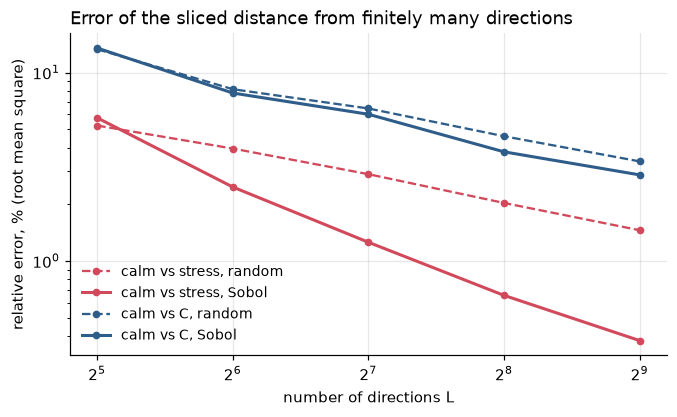

check 2 passed: at 256 directions Sobol cuts the error at least twofold when volatility changes (factor 3.1)
check 3 passed: for correlation-only changes the gain is small (factors 1.21 and 1.16)


In [4]:
def random_directions(n_dir, dim, seed):
    g = np.random.default_rng(seed).standard_normal((n_dir, dim))
    return g / np.linalg.norm(g, axis=1, keepdims=True)


def sobol_directions(n_dir, dim, seed):
    # Scrambled Sobol points mapped through the normal quantile function and normalised to unit length.
    u = qmc.Sobol(dim, scramble=True, seed=seed).random(n_dir)
    g = norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))
    return g / np.linalg.norm(g, axis=1, keepdims=True)


def gaussian_sw(S1, S2, dirs):
    v1, v2 = np.einsum("li,ij,lj->l", dirs, S1, dirs), np.einsum("li,ij,lj->l", dirs, S2, dirs)
    return np.sqrt(np.mean((np.sqrt(v1) - np.sqrt(v2)) ** 2))


sizes = [32, 64, 128, 256, 512]
qmc_error = {}
for other in ["stress", "C", "F"]:
    S1, S2 = covariance("calm"), covariance(other)
    truth = gaussian_sw(S1, S2, sobol_directions(2**18, N_ASSETS, 999))
    for kind, make in [("random", random_directions), ("Sobol", sobol_directions)]:
        err = [[gaussian_sw(S1, S2, make(L, N_ASSETS, seed)) / truth - 1 for seed in range(100)] for L in sizes]
        qmc_error[(other, kind)] = np.sqrt(np.mean(np.square(err), axis=1))
    print(f"calm vs {other:6s} SW2 {truth:.4f}   relative error at L = 256, random "
          f"{qmc_error[(other, 'random')][3]:.4f}, Sobol {qmc_error[(other, 'Sobol')][3]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
for other, color in [("stress", STATE_COLORS[2]), ("C", "#2F5D8A")]:
    ax.plot(sizes, qmc_error[(other, "random")] * 100, color=color, lw=1.5, ls="--", marker="o", ms=4,
            label=f"calm vs {other}, random")
    ax.plot(sizes, qmc_error[(other, "Sobol")] * 100, color=color, lw=2, marker="o", ms=4, label=f"calm vs {other}, Sobol")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("number of directions L")
ax.set_ylabel("relative error, % (root mean square)")
ax.legend(frameon=False, fontsize=9)
ax.set_title("Error of the sliced distance from finitely many directions", loc="left")
plt.show()
gain = {o: qmc_error[(o, "random")][3] / qmc_error[(o, "Sobol")][3] for o in ["stress", "C", "F"]}
check("at 256 directions Sobol cuts the error at least twofold when volatility changes", gain["stress"] >= 2,
      f"(factor {gain['stress']:.1f})")
check("for correlation-only changes the gain is small", max(gain["C"], gain["F"]) < 1.6,
      f"(factors {gain['C']:.2f} and {gain['F']:.2f})")

The figure shows the root mean square relative error of the sliced distance against the number of directions, for random directions (dashed) and scrambled Sobol directions (solid), when the calm regime is compared with the stress regime (red) and with the correlation-only regime C (blue). Both axes are logarithmic.

When volatility changes, every direction sees a gap of roughly the same size, the integrand is smooth and nearly constant, and Sobol directions cut the error almost threefold at 256 directions. When only correlations change, the gap is large along a few directions and small elsewhere. That integrand is rougher, and the gain is only about a fifth. Evenly spread directions remove most of the luck from the volatility part of the fingerprint, and much less from the part that the shape fingerprint below depends on. Section 8 shows what this means for the labels.

## 4. A second fingerprint for shape

The companion notebook found that the volatility fingerprint is dominated by volatility, so a change in how assets move together barely moves it. The fix it suggested is to remove each asset's volatility inside the window before comparing.

#### Standardise inside the window

For the five-session window of day $t$, let $\bar r_{t,i}$ and $\hat s_{t,i}$ be the mean and standard deviation of asset $i$ over the window's 390 bars, and

$$
\tilde z_{s,j,i} = \frac{r_{s,j,i} - \bar r_{t,i}}{\hat s_{t,i}}
$$

Every asset now has mean zero and variance one in every window, whatever the market's volatility. The shape fingerprint $\psi_t$ is built from $\tilde z$ exactly as $\phi_t$ is built from $z$, with the same directions.

#### What the shape fingerprint measures

The variance of a projection $\theta^\top \tilde z$ is $\theta^\top R_t\, \theta$, where $R_t$ is the window's correlation matrix. For a uniform direction $E[\theta \theta^\top] = I_d / d$, so its average over directions is

$$
E_\theta\big[\theta^\top R\, \theta\big] = \frac{\operatorname{tr} R}{d} = 1
$$

for every window. The level carries no information. What differs between windows is the spread across directions. A standard moment of the uniform distribution on the sphere gives $E[(\theta^\top A \theta)^2] = \big((\operatorname{tr} A)^2 + 2 \operatorname{tr} A^2\big) / \big(d(d+2)\big)$ for a symmetric matrix $A$, and with $\operatorname{tr} R = d$ this becomes

$$
\operatorname{Var}_\theta\big(\theta^\top R\, \theta\big) = \frac{2}{d(d+2)} \sum_{i=1}^{d} (\lambda_i - 1)^2
$$

where $\lambda_1 \ge \dots \ge \lambda_d$ are the eigenvalues of $R$. Uncorrelated assets have all $\lambda_i = 1$, so every projection has variance one and the fingerprints of different windows only differ in their tails. When the assets move as one block, the first eigenvalue grows and the projections along that block become much wider than the rest.

#### Concentration

The brake summarises that block by the share of the first eigenvalue

$$
\kappa_t = \frac{\lambda_1(R_t)}{d} \in \Big[\frac{1}{d},\, 1\Big]
$$

This is the one-factor version of the absorption ratio of Kritzman, Li, Page and Rigobon (2011), the share of total variance that the largest principal components absorb. A high $\kappa$ means that diversification has gone, which is what crashes look like.

The next cell checks the variance formula on the synthetic market's correlation matrices and checks that the shape fingerprint does not change when any asset's returns are multiplied by a positive constant.

In [5]:
def standardise(W):
    # Each column to mean 0 and sd 1 within the window. Columns with no movement become 0.
    mu, sd = np.nanmean(W, axis=0), np.nanstd(W, axis=0)
    Z = np.zeros_like(W)
    ok = sd > 0
    Z[:, ok] = (W[:, ok] - mu[ok]) / sd[ok]
    return np.nan_to_num(Z)


def concentration(Z):
    # Share of the largest eigenvalue of the window's correlation matrix.
    keep = Z.std(axis=0) > 0
    return np.linalg.eigvalsh(np.corrcoef(Z[:, keep], rowvar=False))[-1] / Z.shape[1]


def shape_fingerprints(X, dirs, window=5, first=0):
    # Shape fingerprint and concentration of the last `window` days for every day from `first` on.
    F, kappa = np.full((len(X), len(dirs) * len(QL)), np.nan), np.full(len(X), np.nan)
    for t in range(max(first, window - 1), len(X)):
        Z = standardise(X[t - window + 1:t + 1].reshape(-1, X.shape[2]))
        F[t] = fingerprint(Z, dirs)
        kappa[t] = concentration(Z)
    return F, kappa


def correlation(name):
    S = covariance(name)
    sd = np.sqrt(np.diag(S))
    return S / np.outer(sd, sd)


many = random_directions(200_000, N_ASSETS, seed=1)
d = N_ASSETS
for name in ["calm", "C", "F"]:
    R = correlation(name)
    x = np.einsum("li,ij,lj->l", many, R, many)
    lam = np.linalg.eigvalsh(R)
    formula = 2 * np.sum((lam - 1) ** 2) / (d * (d + 2))
    print(f"{name:5s} mean {x.mean():.4f}   variance {x.var():.4f}   formula {formula:.4f}   kappa {lam[-1] / d:.3f}")
    check(f"projection variance spread matches the eigenvalue formula ({name})", abs(x.var() / formula - 1) < 0.02)

rng = np.random.default_rng(3)
W = rng.standard_normal((390, d)) @ np.linalg.cholesky(correlation("C")).T
dirs = sobol_directions(64, d, 0)
gap = np.abs(fingerprint(standardise(W), dirs) - fingerprint(standardise(W * rng.uniform(0.1, 10, d)), dirs)).max()
check("the shape fingerprint ignores each asset's volatility", gap < 1e-12, f"(largest difference {gap:.1e})")

calm  mean 1.0000   variance 0.1618   formula 0.1619   kappa 0.300
check 4 passed: projection variance spread matches the eigenvalue formula (calm) 
C     mean 0.9998   variance 0.2752   formula 0.2754   kappa 0.397
check 5 passed: projection variance spread matches the eigenvalue formula (C) 


F     mean 0.9999   variance 0.1654   formula 0.1658   kappa 0.307
check 6 passed: projection variance spread matches the eigenvalue formula (F) 
check 7 passed: the shape fingerprint ignores each asset's volatility (largest difference 4.2e-17)


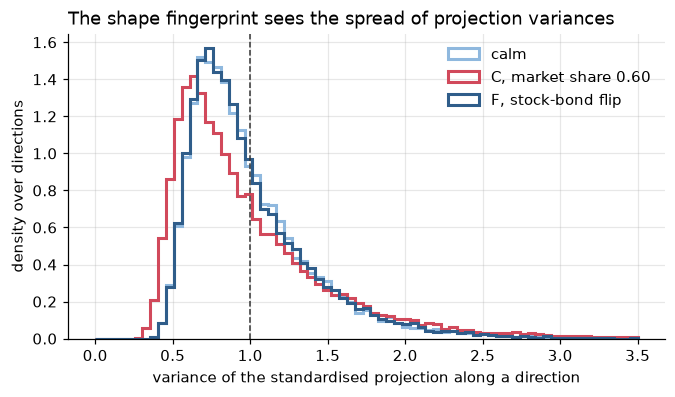

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, 3.5, 70)
for name, color, label in [("calm", STATE_COLORS[0], "calm"), ("C", STATE_COLORS[2], "C, market share 0.60"),
                           ("F", "#2F5D8A", "F, stock-bond flip")]:
    x = np.einsum("li,ij,lj->l", many[:20_000], correlation(name), many[:20_000])
    ax.hist(x, bins=bins, histtype="step", lw=2, color=color, density=True, label=label)
ax.axvline(1, color="0.2", ls="--", lw=1)
ax.set_xlabel("variance of the standardised projection along a direction")
ax.set_ylabel("density over directions")
ax.legend(frameon=False)
ax.set_title("The shape fingerprint sees the spread of projection variances", loc="left")
plt.show()

The figure shows, for 20,000 random directions, the distribution of the variance of the standardised projection $\theta^\top R\, \theta$ under three correlation matrices of the synthetic market. All three average one (dashed line). Under the calm and flipped correlations most directions sit near one. When the market factor's share rises, a long right tail appears, made of the directions that line up with the equity block. The flip moves a few directions only, so its histogram is close to calm, which is why it does not register as concentration even though the shape fingerprint can tell it apart.

## 5. The brake

The brake combines three daily inputs.

#### The volatility state

$s_t \in \{\text{calm}, \text{transition}, \text{stress}\}$ from section 1, with 256 scrambled Sobol directions.

#### The crash shape

Every January, k-means with $K = 3$ runs on the shape fingerprints of the last 504 sessions. The cluster whose training days have the highest mean concentration $\kappa$ is the crash shape, and $c_t = 1$ when day $t$'s nearest shape centroid is that cluster. The other two shapes are left unnamed.

#### Calming

Let $\bar v_s$ be one session's mean scaled variance, the average of $z^2$ over its 78 bars and all assets. The shock is calming when the last two sessions were quieter than the three before them

$$
\text{calming}_t = \Big[ \tfrac12 \big( \bar v_{t-1} + \bar v_t \big) < \tfrac13 \big( \bar v_{t-4} + \bar v_{t-3} + \bar v_{t-2} \big) \Big]
$$

#### The size

Write $\tau_t$ for the last day before $t$ on which the brake was at zero because of stress. Without the release, the size is the labeler's $m_t$ from section 1. The release changes it on one kind of day

$$
\text{calming}_t \;\text{and}\; c_t = 0 \;\text{and}\; \big( s_t = \text{stress} \;\text{or}\; t - \tau_t \le 5 \big) \;\Longrightarrow\; m_t = \begin{cases} 0.5 & s_t = \text{stress} \\ \text{the state's size} & \text{otherwise} \end{cases}
$$

and the wait ends. So on a calming day that does not have the crash shape, stress counts as transition and the five-session wait is cut short. On a crash-shape day nothing changes, and a stress day that is not calming starts the wait again.

Two other brakes serve as references below. The wait-only brake is the labeler of section 1. The plain release applies the release on every calming day, whatever the shape.

The function `brake` applies these rules to a sequence of days. The toy example shows one stress spell twice, once with the crash shape on the calming days and once without.

In [7]:
def brake(state, crash, calm, release=True, use_shape=True, wait=5):
    # Daily size multiplier. state 0/1/2, crash and calm booleans, one entry per session.
    state, crash, calm = np.asarray(state), np.asarray(crash, bool), np.asarray(calm, bool)
    m = np.where(state == 0, 1.0, 0.5)
    last = -10**9
    for i in range(len(m)):
        free = release and calm[i] and not (use_shape and crash[i])
        if free and (state[i] == 2 or i - last <= wait):
            last = -10**9                      # released, the wait ends and the day keeps its table size
        elif state[i] == 2:
            m[i], last = 0.0, i
        elif i - last <= wait:
            m[i] = 0.0
    return m


toy_state = np.array([0, 2, 2, 2, 2, 1, 1, 1, 1, 0, 0, 0])
toy_calm = np.array([0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0], bool)
toy_crash = np.array([0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0], bool)
print("state                ", toy_state)
print("calming              ", toy_calm.astype(int))
print("wait only            ", brake(toy_state, toy_crash, toy_calm, release=False))
print("released, no crash   ", brake(toy_state, np.zeros(12, bool), toy_calm))
print("released, crash shape", brake(toy_state, toy_crash, toy_calm))
check("the release lets go on the first calming day without the crash shape",
      list(brake(toy_state, np.zeros(12, bool), toy_calm)[:6]) == [1, 0, 0, 0.5, 0.5, 0.5])
check("the crash shape holds the brake until the shape changes",
      list(brake(toy_state, toy_crash, toy_calm)[:8]) == [1, 0, 0, 0, 0, 0, 0.5, 0.5])

state                 [0 2 2 2 2 1 1 1 1 0 0 0]
calming               [0 0 0 1 1 1 1 1 1 1 0 0]
wait only             [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1.]
released, no crash    [1.  0.  0.  0.5 0.5 0.5 0.5 0.5 0.5 1.  1.  1. ]
released, crash shape [1.  0.  0.  0.  0.  0.  0.5 0.5 0.5 1.  1.  1. ]
check 8 passed: the release lets go on the first calming day without the crash shape 
check 9 passed: the crash shape holds the brake until the shape changes 


In the toy example the plain labeler stays at zero until five sessions after the last stress day. Without the crash shape the release lets go on day 3, the first calming day, at half size because the day is still stress. With the crash shape on days 1 to 5, the brake holds until day 6, the first calming day with another shape.

## 6. Experiment 1. Does the shape axis see the crash shape, and only that?

For each of the kinds none, V, C, VC and F, 10 synthetic histories are drawn. In each history both sets of clusters are fitted once on the training days 300 to 799, and the test days are labelled. The table gives the share of days in the stress state and in the crash shape over two stretches, the first 30 days once the five-day window lies wholly after the break (days 905 to 934) and all later days (905 to 1,099). The synthetic study uses 64 Sobol directions to keep the run short, which section 3 shows is plenty for 21 assets.

In [8]:
DIRS_SYN = sobol_directions(64, N_ASSETS, 0)
KIND_LIST = list(SCHEDULES)


def calming(v_day, recent=2, before=3):
    v = pd.Series(v_day)
    return (v.rolling(recent).mean() < v.shift(recent).rolling(before).mean()).to_numpy()


def run_history(kind, i):
    X = simulate(kind, np.random.default_rng([31, KIND_LIST.index(kind), i]))
    Z = scale_streams(X, SCALE, SCALE)
    F, v = vol_fingerprints(Z, DIRS_SYN, first=TRAIN[0])
    S, kappa = shape_fingerprints(X, DIRS_SYN, first=TRAIN[0])
    tr, ev = np.arange(*TRAIN), np.arange(EVAL0, DAYS)
    km, rank, _ = fit_ranked(F[tr], v[tr], n_init=4)
    kms, rank_s, _ = fit_ranked(S[tr], kappa[tr], n_init=4)
    state, crash = rank[km.predict(F[ev])], rank_s[kms.predict(S[ev])] == 2
    calm = calming(daily_variance(Z))[ev]
    return {"state": state, "crash": crash, "kappa": kappa[ev], "index_vol": (X[ev, :, :N_EQ].mean(axis=2) ** 2).sum(axis=1),
            "wait only": brake(state, crash, calm, release=False),
            "plain release": brake(state, crash, calm, use_shape=False),
            "shape-conditioned": brake(state, crash, calm)}


t_start = time.time()
N_HIST = 10
results = {kind: [run_history(kind, i) for i in range(N_HIST)] for kind in KIND_LIST}
print(f"{len(KIND_LIST) * N_HIST} histories in {time.time() - t_start:.0f} s")

test_days = np.arange(EVAL0, DAYS)
first30 = (test_days >= BREAK + 5) & (test_days < BREAK + 35)
later = test_days >= BREAK + 5
exp1 = pd.DataFrame({kind: {"stress, first 30": np.mean([np.mean(r["state"][first30] == 2) for r in results[kind]]),
                            "stress, all later": np.mean([np.mean(r["state"][later] == 2) for r in results[kind]]),
                            "crash shape, first 30": np.mean([r["crash"][first30].mean() for r in results[kind]]),
                            "crash shape, all later": np.mean([r["crash"][later].mean() for r in results[kind]]),
                            "mean kappa": np.mean([r["kappa"][later].mean() for r in results[kind]])}
                     for kind in ["none", "V", "C", "VC", "F"]}).T
print("share of days in each label after the break")
print(exp1.round(3).to_string())

70 histories in 147 s
share of days in each label after the break
      stress, first 30  stress, all later  crash shape, first 30  crash shape, all later  mean kappa
none             0.083              0.031                  0.000                   0.005       0.301
V                0.920              0.344                  0.010                   0.003       0.302
C                0.000              0.016                  0.973                   0.979       0.398
VC               0.913              0.391                  0.890                   0.881       0.397
F                0.053              0.042                  0.000                   0.000       0.308


In [9]:
e = exp1
check("a pure volatility shock is stress but not crash shape",
      e.loc["V", "stress, first 30"] >= 0.6 and e.loc["V", "crash shape, all later"] <= 0.05,
      f"(stress {e.loc['V', 'stress, first 30']:.2f}, crash {e.loc['V', 'crash shape, all later']:.2f})")
check("a correlation rise alone is crash shape but not stress",
      e.loc["C", "crash shape, all later"] >= 0.8 and e.loc["C", "stress, first 30"] <= 0.1,
      f"(crash {e.loc['C', 'crash shape, all later']:.2f}, stress {e.loc['C', 'stress, first 30']:.2f})")
check("crash-shaped stress is both", min(e.loc["VC", "stress, first 30"], e.loc["VC", "crash shape, all later"]) >= 0.6)
check("the stock-bond flip looks like no break at all",
      abs(e.loc["F", "stress, first 30"] - e.loc["none", "stress, first 30"]) <= 0.05
      and e.loc[["none", "F"], "crash shape, all later"].max() <= 0.05,
      f"(stress {e.loc['F', 'stress, first 30']:.2f} against {e.loc['none', 'stress, first 30']:.2f} without a break)")
check("the one-year scaling absorbs a lasting volatility rise", e.loc["V", "stress, all later"] < 0.6 * e.loc["V", "stress, first 30"],
      f"({e.loc['V', 'stress, first 30']:.2f} in the first 30 days, {e.loc['V', 'stress, all later']:.2f} over all later days)")

check 10 passed: a pure volatility shock is stress but not crash shape (stress 0.92, crash 0.00)
check 11 passed: a correlation rise alone is crash shape but not stress (crash 0.98, stress 0.00)
check 12 passed: crash-shaped stress is both 
check 13 passed: the stock-bond flip looks like no break at all (stress 0.05 against 0.08 without a break)
check 14 passed: the one-year scaling absorbs a lasting volatility rise (0.92 in the first 30 days, 0.34 over all later days)


The two axes split the four planted changes cleanly. The volatility state reacts to volatility and not to correlation, and the crash shape reacts to correlation and not to volatility. The stress share falls after the first month, because every asset is scaled by its own volatility over the past year, and a volatility level that lasts slowly becomes the new normal. The crash shape does not fade that way, since it is measured inside each window. Histories without a break still spend a few percent of days in stress, from bursts of the GARCH volatility, and the flip histories look the same. The stock–bond flip is invisible to both, because it changes the structure without raising the equity block's share of the variance. Seeing it would need its own named cluster, which this brake does not have.

## 7. Experiment 2. Release after a fading shock, hold through a second leg

Now the two episodes. For each history the table gives the mean size of the three brakes over four stretches of days.

- During the legs crash's bounce, days 906 to 909.
- During its second leg, days 910 to 919.
- In the 15 days after the V shock ends, days 910 to 924.
- Over all test days of the histories without a break, the cost of the brake in a calm market.

In [10]:
def mean_size(kind, brake_name, first, last):
    on = (test_days >= first) & (test_days <= last)
    return np.mean([r[brake_name][on].mean() for r in results[kind]])


brakes = list(BRAKE_COLORS)
exp2 = pd.DataFrame({b: {"legs, bounce": mean_size("legs", b, BREAK + 6, BREAK + 9),
                         "legs, second leg": mean_size("legs", b, BREAK + 10, BREAK + 19),
                         "V shock, 15 days after": mean_size("V shock", b, BREAK + 10, BREAK + 24),
                         "no break, all test days": mean_size("none", b, EVAL0, DAYS)} for b in brakes})
print("mean size multiplier")
print(exp2.round(3).to_string())
bounce_crash = np.mean([r["crash"][(test_days >= BREAK + 6) & (test_days <= BREAK + 9)].mean() for r in results["legs"]])
print(f"\nshare of bounce days in the crash shape {bounce_crash:.2f}")

mean size multiplier
                         wait only  plain release  shape-conditioned
legs, bounce                 0.000          0.500              0.075
legs, second leg             0.010          0.290              0.050
V shock, 15 days after       0.490          0.773              0.727
no break, all test days      0.612          0.621              0.621

share of bounce days in the crash shape 0.88


In [11]:
x = exp2
check("the plain release is back at half size in the bounce", x.loc["legs, bounce", "plain release"] >= 0.4)
check("the shape condition keeps the brake near zero through the second leg",
      x.loc["legs, second leg", "shape-conditioned"] <= 0.2 and x.loc["legs, second leg", "plain release"] >= 0.25,
      f"(shape-conditioned {x.loc['legs, second leg', 'shape-conditioned']:.2f}, "
      f"plain {x.loc['legs, second leg', 'plain release']:.2f})")
check("after a fading volatility shock the shape condition lets go nearly as fast as the plain release, sooner than the wait",
      x.loc["V shock, 15 days after", "plain release"] - x.loc["V shock, 15 days after", "shape-conditioned"] < 0.1
      and x.loc["V shock, 15 days after", "shape-conditioned"] > x.loc["V shock, 15 days after", "wait only"] + 0.15)

check 15 passed: the plain release is back at half size in the bounce 
check 16 passed: the shape condition keeps the brake near zero through the second leg (shape-conditioned 0.05, plain 0.29)
check 17 passed: after a fading volatility shock the shape condition lets go nearly as fast as the plain release, sooner than the wait 


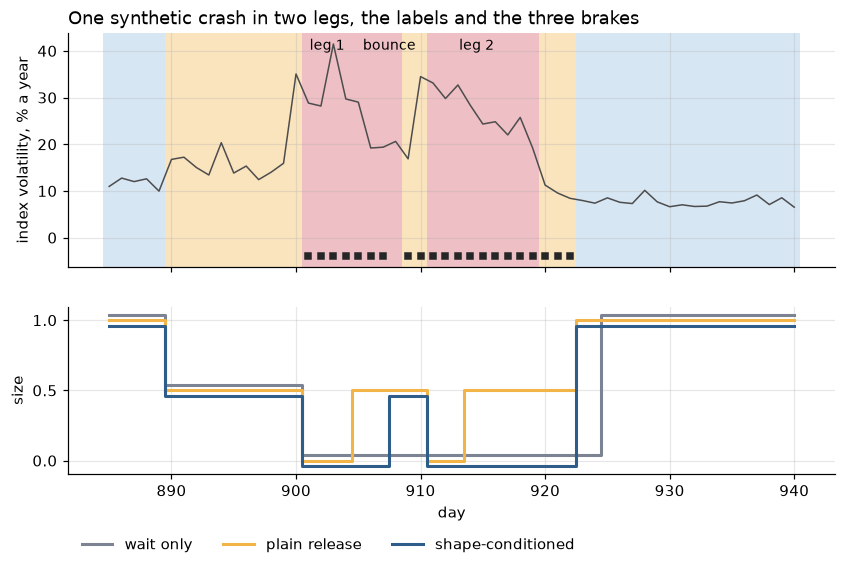

In [12]:
r = results["legs"][0]
show = (test_days >= BREAK - 15) & (test_days <= BREAK + 40)
dd = test_days[show]
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
ax = axes[0]
ax.plot(dd, np.sqrt(252 * r["index_vol"][show]) * 100, color="0.3", lw=1)
for t, s, c in zip(dd, r["state"][show], r["crash"][show]):
    ax.axvspan(t - 0.5, t + 0.5, color=STATE_COLORS[s], alpha=0.35, lw=0)
    if c:
        ax.plot(t, -4, marker="s", color="0.15", ms=4)
for a, b, label in [(BREAK, BREAK + 5, "leg 1"), (BREAK + 6, BREAK + 9, "bounce"), (BREAK + 10, BREAK + 19, "leg 2")]:
    ax.text((a + b) / 2, ax.get_ylim()[1] * 0.92, label, ha="center", fontsize=9)
ax.set_ylabel("index volatility, % a year")
ax.set_title("One synthetic crash in two legs, the labels and the three brakes", loc="left")
ax = axes[1]
for b, off in zip(brakes, [0.04, 0.0, -0.04]):
    ax.step(dd, r[b][show] + off, where="mid", color=BRAKE_COLORS[b], lw=2, label=b)
ax.set_ylabel("size")
ax.set_xlabel("day")
ax.set_yticks([0, 0.5, 1])
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0.0, -0.3))
plt.show()

The figure shows one synthetic legs history around the crash. The top panel has the daily volatility of the equal-weight equity index, the volatility state as shading (blue calm, yellow transition, red stress) and black squares on days in the crash shape. The bottom panel has the size of the three brakes, nudged apart vertically so that equal lines stay visible.

In the bounce volatility falls, so the calming test fires, and the plain release goes back to half size just before the second leg. The shape-conditioned brake sees that the assets still move as one block and holds. After the V shock, where the crash shape rarely appears, both releases let go as soon as volatility falls, the shape-conditioned one a little later in a few histories, while the wait-only brake sits at zero for five more sessions.

This experiment shows that the rule does what it was built to do in a market built to match it, where the correlation stays high through the bounce. Whether real crashes behave like that is the question of the next section.

## 8. Real data

The brake was run walk-forward on five-minute bars of 23 US-listed ETFs from January 2016 to October 2026, plus two spreads built from them, the same 25 streams as in the companion notebook.

- Broad equity SPY, QQQ, IWM and EFA.
- Nine sector funds, XLK, XLF, XLE, XLV, XLY, XLP, XLI, XLU and XLB.
- Treasuries SHY, IEF and TLT, credit HYG and LQD, and inflation-linked TIP.
- Dollar UUP, gold GLD, oil USO and commodities DBC.
- CREDIT, the return of HYG minus IEF, and BEI, the return of TIP minus IEF.

Bars are consolidated-tape bars of the regular session, 78 a day, adjusted for splits and dividends, with half-day sessions left out. The settings are those of sections 1 to 5, with 256 scrambled Sobol directions (seed 0), 20 quantiles, five-session windows and a January refit on the last 504 sessions. The first labels are for 2 January 2018. That first refit had only 376 sessions of history to train on, since the data starts in 2016.

The cell below holds results computed from the original run, since the data cannot be redistributed. These are the runs of each label, weekly SPY realised volatility for the figures, the refits, three events day by day and summary tables.

In [13]:
REAL = {'first': '2018-01-02',
 'last': '2026-10-28',
 'n_days': 2200,
 'runs': {'state': [['2018-01-02', 0.0], ['2018-01-05', 1.0], ['2018-01-25', 2.0], ['2018-03-15', 1.0],
                    ['2018-03-16', 2.0], ['2018-04-17', 1.0], ['2018-04-24', 2.0], ['2018-05-01', 1.0],
                    ['2018-05-03', 2.0], ['2018-05-07', 1.0], ['2018-05-08', 2.0], ['2018-05-09', 1.0],
                    ['2018-05-22', 0.0], ['2018-05-23', 1.0], ['2018-06-14', 0.0], ['2018-06-15', 1.0],
                    ['2018-07-18', 0.0], ['2018-07-24', 1.0], ['2018-08-06', 0.0], ['2018-08-15', 1.0],
                    ['2018-08-22', 0.0], ['2018-09-05', 1.0], ['2018-09-14', 0.0], ['2018-10-03', 1.0],
                    ['2018-10-10', 2.0], ['2018-11-08', 1.0], ['2018-11-13', 2.0], ['2018-11-29', 1.0],
                    ['2018-12-03', 2.0], ['2019-01-02', 1.0], ['2019-01-11', 0.0], ['2019-05-13', 1.0],
                    ['2019-05-14', 0.0], ['2019-08-05', 1.0], ['2019-08-20', 0.0], ['2020-01-31', 1.0],
                    ['2020-02-06', 0.0], ['2020-02-25', 1.0], ['2020-02-27', 2.0], ['2020-04-01', 1.0],
                    ['2020-04-17', 0.0], ['2020-04-21', 1.0], ['2020-04-28', 0.0], ['2020-06-16', 1.0],
                    ['2020-06-17', 0.0], ['2021-10-04', 1.0], ['2021-10-07', 0.0], ['2021-11-30', 1.0],
                    ['2021-12-10', 0.0], ['2021-12-16', 1.0], ['2021-12-23', 0.0], ['2022-01-27', 1.0],
                    ['2022-01-31', 0.0], ['2023-01-06', 1.0], ['2023-01-09', 0.0], ['2023-02-07', 1.0],
                    ['2023-02-08', 0.0], ['2023-03-13', 1.0], ['2023-03-16', 2.0], ['2023-03-20', 1.0],
                    ['2023-03-29', 0.0], ['2023-10-03', 1.0], ['2023-10-11', 0.0], ['2023-10-18', 1.0],
                    ['2023-11-06', 0.0], ['2023-12-05', 1.0], ['2023-12-07', 0.0], ['2024-02-02', 1.0],
                    ['2024-02-08', 0.0], ['2024-04-09', 1.0], ['2024-04-26', 0.0], ['2024-05-01', 1.0],
                    ['2024-05-07', 0.0], ['2024-06-05', 1.0], ['2024-06-07', 0.0], ['2024-07-18', 1.0],
                    ['2024-08-05', 2.0], ['2024-08-12', 1.0], ['2024-08-15', 0.0], ['2024-08-23', 1.0],
                    ['2024-08-26', 0.0], ['2024-09-04', 1.0], ['2024-09-25', 0.0], ['2024-10-01', 1.0],
                    ['2024-10-09', 0.0], ['2024-11-01', 1.0], ['2024-12-02', 0.0], ['2024-12-18', 1.0],
                    ['2025-01-08', 2.0], ['2025-01-16', 1.0], ['2025-01-24', 0.0], ['2025-01-27', 1.0],
                    ['2025-02-03', 2.0], ['2025-02-05', 1.0], ['2025-02-14', 0.0], ['2025-02-24', 1.0],
                    ['2025-02-27', 2.0], ['2025-03-20', 1.0], ['2025-04-01', 2.0], ['2025-04-28', 1.0],
                    ['2025-05-15', 0.0], ['2025-05-22', 1.0], ['2025-05-29', 0.0], ['2025-06-18', 1.0],
                    ['2025-06-26', 0.0], ['2025-10-14', 1.0], ['2025-10-24', 0.0], ['2025-11-18', 1.0],
                    ['2025-12-01', 0.0], ['2026-01-30', 1.0], ['2026-02-10', 0.0], ['2026-03-03', 1.0],
                    ['2026-03-18', 0.0], ['2026-03-19', 1.0], ['2026-04-10', 0.0], ['2026-04-23', 1.0],
                    ['2026-04-28', 0.0], ['2026-05-04', 1.0], ['2026-05-08', 0.0], ['2026-05-18', 1.0],
                    ['2026-05-29', 0.0], ['2026-06-09', 1.0], ['2026-07-02', 0.0], ['2026-07-29', 1.0],
                    ['2026-08-05', 0.0], ['2026-09-25', 1.0], ['2026-10-08', 0.0], ['2026-10-20', 1.0],
                    ['2026-10-27', 0.0]],
          'crash': [['2018-01-02', 0.0], ['2018-02-02', 1.0], ['2018-02-09', 0.0], ['2018-02-16', 1.0],
                    ['2018-03-06', 0.0], ['2018-05-17', 1.0], ['2018-05-22', 0.0], ['2018-06-13', 1.0],
                    ['2018-06-14', 0.0], ['2019-01-02', 1.0], ['2019-01-16', 0.0], ['2019-01-18', 1.0],
                    ['2019-01-30', 0.0], ['2019-03-08', 1.0], ['2019-03-12', 0.0], ['2019-03-25', 1.0],
                    ['2019-04-01', 0.0], ['2019-05-09', 1.0], ['2019-05-24', 0.0], ['2019-05-30', 1.0],
                    ['2019-06-05', 0.0], ['2019-08-06', 1.0], ['2019-08-22', 0.0], ['2019-08-26', 1.0],
                    ['2019-09-04', 0.0], ['2019-10-02', 1.0], ['2019-10-14', 0.0], ['2020-01-27', 1.0],
                    ['2020-02-10', 0.0], ['2020-02-13', 1.0], ['2020-02-14', 0.0], ['2020-02-24', 1.0],
                    ['2020-03-09', 0.0], ['2020-03-10', 1.0], ['2020-03-12', 0.0], ['2020-03-19', 1.0],
                    ['2020-04-30', 0.0], ['2020-05-04', 1.0], ['2020-05-05', 0.0], ['2020-05-06', 1.0],
                    ['2020-05-11', 0.0], ['2020-05-12', 1.0], ['2020-05-26', 0.0], ['2020-05-28', 1.0],
                    ['2020-05-29', 0.0], ['2020-06-11', 1.0], ['2020-07-21', 0.0], ['2020-09-04', 1.0],
                    ['2020-09-17', 0.0], ['2020-09-23', 1.0], ['2020-10-06', 0.0], ['2020-10-19', 1.0],
                    ['2020-11-06', 0.0], ['2021-10-06', 1.0], ['2021-10-08', 0.0], ['2021-12-03', 1.0],
                    ['2021-12-09', 0.0], ['2021-12-20', 1.0], ['2021-12-27', 0.0], ['2022-02-22', 1.0],
                    ['2022-02-28', 0.0], ['2023-01-03', 1.0], ['2023-03-16', 0.0], ['2023-08-14', 1.0],
                    ['2023-08-23', 0.0], ['2023-08-25', 1.0], ['2023-09-05', 0.0], ['2023-09-25', 1.0],
                    ['2023-11-08', 0.0], ['2023-11-09', 1.0], ['2023-11-16', 0.0], ['2023-11-29', 1.0],
                    ['2023-12-06', 0.0], ['2023-12-13', 1.0], ['2023-12-18', 0.0], ['2023-12-22', 1.0],
                    ['2024-01-02', 0.0], ['2024-01-08', 1.0], ['2024-01-22', 0.0], ['2024-04-10', 1.0],
                    ['2024-04-24', 0.0], ['2024-05-02', 1.0], ['2024-05-08', 0.0], ['2024-12-23', 1.0],
                    ['2025-01-02', 0.0], ['2025-01-07', 1.0], ['2025-01-17', 0.0], ['2025-05-22', 1.0],
                    ['2025-05-29', 0.0], ['2026-01-30', 1.0], ['2026-02-11', 0.0], ['2026-02-13', 1.0],
                    ['2026-02-25', 0.0]],
          'mult': [['2018-01-02', 1.0], ['2018-01-05', 0.5], ['2018-01-25', 0.0], ['2018-01-29', 0.5],
                   ['2018-01-30', 0.0], ['2018-02-09', 0.5], ['2018-02-16', 0.0], ['2018-03-06', 0.5],
                   ['2018-03-14', 0.0], ['2018-03-16', 0.5], ['2018-03-20', 0.0], ['2018-04-02', 0.5],
                   ['2018-04-24', 0.0], ['2018-04-26', 0.5], ['2018-05-03', 0.0], ['2018-05-07', 0.5],
                   ['2018-05-22', 1.0], ['2018-05-23', 0.5], ['2018-06-14', 1.0], ['2018-06-15', 0.5],
                   ['2018-07-18', 1.0], ['2018-07-24', 0.5], ['2018-08-06', 1.0], ['2018-08-15', 0.5],
                   ['2018-08-22', 1.0], ['2018-09-05', 0.5], ['2018-09-14', 1.0], ['2018-10-03', 0.5],
                   ['2018-10-10', 0.0], ['2018-10-15', 0.5], ['2018-10-18', 0.0], ['2018-10-22', 0.5],
                   ['2018-10-24', 0.0], ['2018-10-31', 0.5], ['2018-11-13', 0.0], ['2018-11-16', 0.5],
                   ['2018-11-20', 0.0], ['2018-11-21', 0.5], ['2018-11-28', 0.0], ['2018-11-30', 0.5],
                   ['2018-12-04', 0.0], ['2018-12-11', 0.5], ['2018-12-17', 0.0], ['2018-12-26', 0.5],
                   ['2019-01-11', 1.0], ['2019-05-13', 0.5], ['2019-05-14', 1.0], ['2019-08-05', 0.5],
                   ['2019-08-20', 1.0], ['2020-01-31', 0.5], ['2020-02-06', 1.0], ['2020-02-25', 0.5],
                   ['2020-02-27', 0.0], ['2020-03-16', 0.5], ['2020-03-19', 0.0], ['2020-04-08', 0.5],
                   ['2020-04-17', 1.0], ['2020-04-21', 0.5], ['2020-04-28', 1.0], ['2020-06-16', 0.5],
                   ['2020-06-17', 1.0], ['2021-10-04', 0.5], ['2021-10-07', 1.0], ['2021-11-30', 0.5],
                   ['2021-12-10', 1.0], ['2021-12-16', 0.5], ['2021-12-23', 1.0], ['2022-01-27', 0.5],
                   ['2022-01-31', 1.0], ['2023-01-06', 0.5], ['2023-01-09', 1.0], ['2023-02-07', 0.5],
                   ['2023-02-08', 1.0], ['2023-03-13', 0.5], ['2023-03-16', 0.0], ['2023-03-17', 0.5],
                   ['2023-03-29', 1.0], ['2023-10-03', 0.5], ['2023-10-11', 1.0], ['2023-10-18', 0.5],
                   ['2023-11-06', 1.0], ['2023-12-05', 0.5], ['2023-12-07', 1.0], ['2024-02-02', 0.5],
                   ['2024-02-08', 1.0], ['2024-04-09', 0.5], ['2024-04-26', 1.0], ['2024-05-01', 0.5],
                   ['2024-05-07', 1.0], ['2024-06-05', 0.5], ['2024-06-07', 1.0], ['2024-07-18', 0.5],
                   ['2024-08-05', 0.0], ['2024-08-07', 0.5], ['2024-08-15', 1.0], ['2024-08-23', 0.5],
                   ['2024-08-26', 1.0], ['2024-09-04', 0.5], ['2024-09-25', 1.0], ['2024-10-01', 0.5],
                   ['2024-10-09', 1.0], ['2024-11-01', 0.5], ['2024-12-02', 1.0], ['2024-12-18', 0.5],
                   ['2025-01-08', 0.0], ['2025-01-17', 0.5], ['2025-01-24', 1.0], ['2025-01-27', 0.5],
                   ['2025-02-03', 0.0], ['2025-02-05', 0.5], ['2025-02-14', 1.0], ['2025-02-24', 0.5],
                   ['2025-02-27', 0.0], ['2025-03-10', 0.5], ['2025-04-01', 0.0], ['2025-04-09', 0.5],
                   ['2025-04-23', 0.0], ['2025-04-25', 0.5], ['2025-05-15', 1.0], ['2025-05-22', 0.5],
                   ['2025-05-29', 1.0], ['2025-06-18', 0.5], ['2025-06-26', 1.0], ['2025-10-14', 0.5],
                   ['2025-10-24', 1.0], ['2025-11-18', 0.5], ['2025-12-01', 1.0], ['2026-01-30', 0.5],
                   ['2026-02-10', 1.0], ['2026-03-03', 0.5], ['2026-03-18', 1.0], ['2026-03-19', 0.5],
                   ['2026-04-10', 1.0], ['2026-04-23', 0.5], ['2026-04-28', 1.0], ['2026-05-04', 0.5],
                   ['2026-05-08', 1.0], ['2026-05-18', 0.5], ['2026-05-29', 1.0], ['2026-06-09', 0.5],
                   ['2026-07-02', 1.0], ['2026-07-29', 0.5], ['2026-08-05', 1.0], ['2026-09-25', 0.5],
                   ['2026-10-08', 1.0], ['2026-10-20', 0.5], ['2026-10-27', 1.0]],
          'sw5': [['2018-01-02', 1.0], ['2018-01-05', 0.5], ['2018-01-19', 0.0], ['2018-05-16', 0.5],
                  ['2018-05-22', 1.0], ['2018-05-23', 0.5], ['2018-06-14', 1.0], ['2018-06-15', 0.5],
                  ['2018-07-18', 1.0], ['2018-07-25', 0.5], ['2018-08-06', 1.0], ['2018-08-15', 0.5],
                  ['2018-08-22', 1.0], ['2018-09-05', 0.5], ['2018-09-14', 1.0], ['2018-10-04', 0.5],
                  ['2018-10-10', 0.0], ['2019-01-09', 0.5], ['2019-01-11', 1.0], ['2019-05-13', 0.5],
                  ['2019-05-14', 1.0], ['2019-08-05', 0.5], ['2019-08-20', 1.0], ['2020-01-31', 0.5],
                  ['2020-02-06', 1.0], ['2020-02-25', 0.5], ['2020-02-27', 0.0], ['2020-04-07', 0.5],
                  ['2020-04-17', 1.0], ['2020-04-21', 0.5], ['2020-04-28', 1.0], ['2020-06-16', 0.5],
                  ['2020-06-18', 1.0], ['2021-10-04', 0.5], ['2021-10-08', 1.0], ['2021-11-30', 0.5],
                  ['2021-12-10', 1.0], ['2021-12-16', 0.5], ['2021-12-23', 1.0], ['2022-01-06', 0.5],
                  ['2022-06-08', 1.0], ['2022-06-10', 0.5], ['2022-07-21', 1.0], ['2022-07-22', 0.5],
                  ['2022-07-28', 1.0], ['2022-08-02', 0.5], ['2022-08-03', 1.0], ['2022-09-01', 0.5],
                  ['2022-09-09', 1.0], ['2022-09-21', 0.5], ['2022-10-28', 1.0], ['2022-11-02', 0.5],
                  ['2022-11-03', 1.0], ['2022-11-04', 0.5], ['2022-11-09', 1.0], ['2022-11-10', 0.5],
                  ['2022-11-11', 1.0], ['2023-01-06', 0.5], ['2023-01-09', 1.0], ['2023-02-07', 0.5],
                  ['2023-02-08', 1.0], ['2023-03-13', 0.5], ['2023-03-16', 0.0], ['2023-03-27', 0.5],
                  ['2023-03-29', 1.0], ['2023-10-03', 0.5], ['2023-10-11', 1.0], ['2023-10-18', 0.5],
                  ['2023-11-06', 1.0], ['2023-12-05', 0.5], ['2023-12-07', 1.0], ['2024-02-02', 0.5],
                  ['2024-02-08', 1.0], ['2024-04-09', 0.5], ['2024-04-26', 1.0], ['2024-05-01', 0.5],
                  ['2024-05-07', 1.0], ['2024-06-05', 0.5], ['2024-06-06', 1.0], ['2024-07-18', 0.5],
                  ['2024-08-05', 0.0], ['2024-08-19', 1.0], ['2024-08-23', 0.5], ['2024-08-26', 1.0],
                  ['2024-09-03', 0.5], ['2024-09-25', 1.0], ['2024-10-01', 0.5], ['2024-10-09', 1.0],
                  ['2024-11-01', 0.5], ['2024-12-02', 1.0], ['2024-12-18', 0.5], ['2025-01-07', 0.0],
                  ['2025-01-24', 1.0], ['2025-01-27', 0.5], ['2025-01-31', 0.0], ['2025-02-12', 0.5],
                  ['2025-02-14', 1.0], ['2025-02-19', 0.5], ['2025-02-20', 1.0], ['2025-02-21', 0.5],
                  ['2025-02-27', 0.0], ['2025-03-27', 0.5], ['2025-04-01', 0.0], ['2025-05-06', 0.5],
                  ['2025-05-15', 1.0], ['2025-05-22', 0.5], ['2025-05-29', 1.0], ['2025-06-18', 0.5],
                  ['2025-06-26', 1.0], ['2025-10-14', 0.5], ['2025-10-24', 1.0], ['2025-11-18', 0.5],
                  ['2025-12-01', 1.0], ['2026-01-30', 0.5], ['2026-02-10', 1.0], ['2026-03-03', 0.5],
                  ['2026-03-18', 1.0], ['2026-03-19', 0.5], ['2026-04-08', 1.0], ['2026-04-09', 0.5],
                  ['2026-04-10', 1.0], ['2026-04-23', 0.5], ['2026-04-24', 1.0], ['2026-05-18', 0.5],
                  ['2026-05-28', 1.0], ['2026-06-09', 0.5], ['2026-07-02', 1.0], ['2026-07-29', 0.5],
                  ['2026-08-05', 1.0], ['2026-09-28', 0.5], ['2026-10-08', 1.0], ['2026-10-20', 0.5],
                  ['2026-10-23', 1.0], ['2026-10-26', 0.5], ['2026-10-27', 1.0]]},
 'weekly_vol': [['2018-01-05', 4.54], ['2018-01-12', 4.86], ['2018-01-19', 7.06], ['2018-01-26', 7.32],
                ['2018-02-02', 10.07], ['2018-02-09', 34.6], ['2018-02-16', 15.94], ['2018-02-23', 13.41],
                ['2018-03-02', 16.85], ['2018-03-09', 10.88], ['2018-03-16', 10.14], ['2018-03-23', 14.76],
                ['2018-04-06', 19.27], ['2018-04-13', 13.87], ['2018-04-20', 9.21], ['2018-04-27', 13.34],
                ['2018-05-04', 11.96], ['2018-05-11', 8.46], ['2018-05-18', 7.67], ['2018-05-25', 7.53],
                ['2018-06-01', 8.86], ['2018-06-08', 6.58], ['2018-06-15', 5.92], ['2018-06-22', 7.01],
                ['2018-06-29', 11.71], ['2018-07-06', 9.29], ['2018-07-13', 5.81], ['2018-07-20', 5.2],
                ['2018-07-27', 6.75], ['2018-08-03', 6.23], ['2018-08-10', 5.27], ['2018-08-17', 7.58],
                ['2018-08-24', 4.89], ['2018-08-31', 5.54], ['2018-09-07', 8.59], ['2018-09-14', 6.05],
                ['2018-09-21', 4.9], ['2018-09-28', 5.71], ['2018-10-05', 7.99], ['2018-10-12', 20.53],
                ['2018-10-19', 14.91], ['2018-10-26', 20.2], ['2018-11-02', 20.36], ['2018-11-09', 10.05],
                ['2018-11-16', 18.11], ['2018-11-30', 11.52], ['2018-12-07', 18.97], ['2018-12-14', 19.47],
                ['2018-12-21', 29.44], ['2018-12-28', 30.65], ['2019-01-04', 21.95], ['2019-01-11', 13.21],
                ['2019-01-18', 10.32], ['2019-01-25', 11.35], ['2019-02-01', 11.1], ['2019-02-08', 9.08],
                ['2019-02-15', 7.63], ['2019-02-22', 6.91], ['2019-03-01', 6.81], ['2019-03-08', 10.29],
                ['2019-03-15', 6.5], ['2019-03-22', 11.25], ['2019-03-29', 10.59], ['2019-04-05', 6.09],
                ['2019-04-12', 5.44], ['2019-04-26', 6.13], ['2019-05-03', 7.55], ['2019-05-10', 14.21],
                ['2019-05-17', 12.1], ['2019-05-24', 8.65], ['2019-05-31', 9.89], ['2019-06-07', 10.99],
                ['2019-06-14', 7.76], ['2019-06-21', 7.88], ['2019-06-28', 6.31], ['2019-07-05', 6.66],
                ['2019-07-12', 5.36], ['2019-07-19', 6.2], ['2019-07-26', 5.83], ['2019-08-02', 13.77],
                ['2019-08-09', 15.62], ['2019-08-16', 15.95], ['2019-08-23', 13.22], ['2019-08-30', 10.35],
                ['2019-09-06', 8.6], ['2019-09-13', 7.62], ['2019-09-20', 8.1], ['2019-09-27', 11.07],
                ['2019-10-04', 13.18], ['2019-10-11', 11.06], ['2019-10-18', 6.74], ['2019-10-25', 5.47],
                ['2019-11-01', 6.61], ['2019-11-08', 5.64], ['2019-11-15', 5.06], ['2019-11-22', 6.19],
                ['2019-12-06', 7.95], ['2019-12-13', 8.93], ['2019-12-20', 3.88], ['2019-12-27', 3.53],
                ['2020-01-03', 7.15], ['2020-01-10', 6.25], ['2020-01-17', 5.2], ['2020-01-24', 7.64],
                ['2020-01-31', 10.94], ['2020-02-07', 8.08], ['2020-02-14', 6.97], ['2020-02-21', 9.75],
                ['2020-02-28', 38.69], ['2020-03-06', 42.87], ['2020-03-13', 67.42], ['2020-03-20', 76.43],
                ['2020-03-27', 59.81], ['2020-04-03', 34.01], ['2020-04-17', 21.92], ['2020-04-24', 20.08],
                ['2020-05-01', 17.27], ['2020-05-08', 14.21], ['2020-05-15', 20.78], ['2020-05-22', 14.08],
                ['2020-05-29', 16.64], ['2020-06-05', 11.05], ['2020-06-12', 23.46], ['2020-06-19', 21.81],
                ['2020-06-26', 18.56], ['2020-07-10', 13.77], ['2020-07-17', 16.75], ['2020-07-24', 11.74],
                ['2020-07-31', 11.44], ['2020-08-07', 8.82], ['2020-08-14', 10.22], ['2020-08-21', 7.23],
                ['2020-08-28', 8.99], ['2020-09-04', 23.2], ['2020-09-11', 26.04], ['2020-09-18', 14.28],
                ['2020-09-25', 18.7], ['2020-10-02', 15.65], ['2020-10-09', 12.99], ['2020-10-16', 11.11],
                ['2020-10-23', 14.35], ['2020-10-30', 20.49], ['2020-11-06', 17.18], ['2020-11-13', 16.77],
                ['2020-11-20', 10.79], ['2020-12-04', 9.28], ['2020-12-11', 9.96], ['2020-12-18', 9.01],
                ['2021-01-08', 14.85], ['2021-01-15', 9.97], ['2021-01-22', 8.75], ['2021-01-29', 18.41],
                ['2021-02-05', 9.87], ['2021-02-12', 8.79], ['2021-02-19', 8.68], ['2021-02-26', 18.12],
                ['2021-03-05', 20.85], ['2021-03-12', 13.33], ['2021-03-19', 11.07], ['2021-03-26', 12.08],
                ['2021-04-09', 5.56], ['2021-04-16', 6.32], ['2021-04-23', 9.83], ['2021-04-30', 7.09],
                ['2021-05-07', 9.6], ['2021-05-14', 13.61], ['2021-05-21', 11.76], ['2021-05-28', 5.32],
                ['2021-06-04', 6.08], ['2021-06-11', 5.42], ['2021-06-18', 10.32], ['2021-06-25', 5.22],
                ['2021-07-02', 3.84], ['2021-07-09', 8.22], ['2021-07-16', 7.12], ['2021-07-23', 8.99],
                ['2021-07-30', 7.55], ['2021-08-06', 6.1], ['2021-08-13', 4.17], ['2021-08-20', 9.96],
                ['2021-08-27', 5.08], ['2021-09-03', 4.63], ['2021-09-10', 7.11], ['2021-09-17', 9.97],
                ['2021-09-24', 12.44], ['2021-10-01', 13.32], ['2021-10-08', 13.79], ['2021-10-15', 9.4],
                ['2021-10-22', 6.48], ['2021-10-29', 7.07], ['2021-11-05', 7.3], ['2021-11-12', 7.49],
                ['2021-11-19', 6.65], ['2021-12-03', 18.98], ['2021-12-10', 10.34], ['2021-12-17', 14.93],
                ['2021-12-31', 7.24], ['2022-01-07', 11.04], ['2022-01-14', 13.85], ['2022-01-21', 17.78],
                ['2022-01-28', 32.91], ['2022-02-04', 16.06], ['2022-02-11', 16.83], ['2022-02-18', 15.32],
                ['2022-02-25', 23.62], ['2022-03-04', 21.09], ['2022-03-11', 21.8], ['2022-03-18', 17.59],
                ['2022-03-25', 13.07], ['2022-04-01', 11.32], ['2022-04-08', 13.81], ['2022-04-22', 15.53],
                ['2022-04-29', 21.42], ['2022-05-06', 28.31], ['2022-05-13', 28.57], ['2022-05-20', 22.74],
                ['2022-05-27', 18.11], ['2022-06-03', 17.3], ['2022-06-10', 17.39], ['2022-06-17', 27.27],
                ['2022-06-24', 19.04], ['2022-07-01', 21.1], ['2022-07-08', 18.32], ['2022-07-15', 17.03],
                ['2022-07-22', 15.21], ['2022-07-29', 13.85], ['2022-08-05', 13.51], ['2022-08-12', 11.11],
                ['2022-08-19', 10.11], ['2022-08-26', 16.05], ['2022-09-02', 18.35], ['2022-09-09', 17.99],
                ['2022-09-16', 16.24], ['2022-09-23', 23.82], ['2022-09-30', 21.26], ['2022-10-07', 17.55],
                ['2022-10-14', 24.24], ['2022-10-21', 20.0], ['2022-10-28', 17.47], ['2022-11-04', 22.45],
                ['2022-11-11', 16.56], ['2022-11-18', 15.59], ['2022-12-02', 14.23], ['2022-12-09', 13.0],
                ['2022-12-16', 21.55], ['2022-12-23', 14.19], ['2022-12-30', 13.56], ['2023-01-06', 17.55],
                ['2023-01-13', 13.82], ['2023-01-20', 10.98], ['2023-01-27', 13.04], ['2023-02-03', 15.92],
                ['2023-02-10', 14.77], ['2023-02-17', 13.2], ['2023-02-24', 11.84], ['2023-03-03', 10.16],
                ['2023-03-10', 15.33], ['2023-03-17', 21.03], ['2023-03-24', 15.97], ['2023-03-31', 8.4],
                ['2023-04-14', 9.16], ['2023-04-21', 7.75], ['2023-04-28', 8.63], ['2023-05-05', 10.36],
                ['2023-05-12', 9.68], ['2023-05-19', 9.08], ['2023-05-26', 10.0], ['2023-06-02', 9.03],
                ['2023-06-09', 8.01], ['2023-06-16', 9.63], ['2023-06-23', 8.16], ['2023-06-30', 7.69],
                ['2023-07-07', 6.88], ['2023-07-14', 6.97], ['2023-07-21', 6.66], ['2023-07-28', 8.52],
                ['2023-08-04', 8.5], ['2023-08-11', 9.77], ['2023-08-18', 9.26], ['2023-08-25', 10.9],
                ['2023-09-01', 8.35], ['2023-09-08', 8.08], ['2023-09-15', 7.09], ['2023-09-22', 8.73],
                ['2023-09-29', 12.26], ['2023-10-06', 13.13], ['2023-10-13', 10.39], ['2023-10-20', 13.73],
                ['2023-10-27', 13.06], ['2023-11-03', 10.25], ['2023-11-10', 8.58], ['2023-11-17', 6.76],
                ['2023-12-01', 7.65], ['2023-12-08', 7.99], ['2023-12-15', 8.49], ['2023-12-22', 8.07],
                ['2023-12-29', 6.07], ['2024-01-05', 8.28], ['2024-01-12', 8.85], ['2024-01-19', 8.13],
                ['2024-01-26', 7.09], ['2024-02-02', 9.51], ['2024-02-09', 6.54], ['2024-02-16', 8.54],
                ['2024-02-23', 8.75], ['2024-03-01', 6.28], ['2024-03-08', 9.21], ['2024-03-15', 9.34],
                ['2024-03-22', 8.0], ['2024-04-05', 9.84], ['2024-04-12', 11.12], ['2024-04-19', 14.44],
                ['2024-04-26', 9.45], ['2024-05-03', 12.36], ['2024-05-10', 5.42], ['2024-05-17', 6.11],
                ['2024-05-24', 7.43], ['2024-05-31', 8.25], ['2024-06-07', 8.74], ['2024-06-14', 7.99],
                ['2024-06-21', 7.75], ['2024-06-28', 8.19], ['2024-07-05', 8.1], ['2024-07-12', 6.77],
                ['2024-07-19', 10.58], ['2024-07-26', 12.18], ['2024-08-02', 14.16], ['2024-08-09', 20.86],
                ['2024-08-16', 9.81], ['2024-08-23', 10.64], ['2024-08-30', 9.32], ['2024-09-06', 12.3],
                ['2024-09-13', 11.34], ['2024-09-20', 11.41], ['2024-09-27', 6.38], ['2024-10-04', 11.78],
                ['2024-10-11', 6.65], ['2024-10-18', 6.86], ['2024-10-25', 7.85], ['2024-11-01', 9.27],
                ['2024-11-08', 7.84], ['2024-11-15', 8.1], ['2024-11-22', 10.61], ['2024-12-06', 4.53],
                ['2024-12-13', 5.45], ['2024-12-20', 14.99], ['2024-12-27', 13.5], ['2025-01-03', 14.3],
                ['2025-01-10', 13.12], ['2025-01-17', 10.64], ['2025-01-24', 6.09], ['2025-01-31', 12.65],
                ['2025-02-07', 12.35], ['2025-02-14', 6.8], ['2025-02-21', 7.03], ['2025-02-28', 15.62],
                ['2025-03-07', 21.76], ['2025-03-14', 19.68], ['2025-03-21', 13.54], ['2025-03-28', 10.36],
                ['2025-04-04', 25.72], ['2025-04-11', 65.68], ['2025-04-25', 16.34], ['2025-05-02', 14.86],
                ['2025-05-09', 14.36], ['2025-05-16', 9.5], ['2025-05-23', 11.63], ['2025-05-30', 10.99],
                ['2025-06-06', 9.68], ['2025-06-13', 8.54], ['2025-06-20', 9.77], ['2025-06-27', 7.25],
                ['2025-07-11', 6.37], ['2025-07-18', 7.84], ['2025-07-25', 5.23], ['2025-08-01', 9.04],
                ['2025-08-08', 7.97], ['2025-08-15', 6.7], ['2025-08-22', 9.96], ['2025-08-29', 5.61],
                ['2025-09-05', 8.15], ['2025-09-12', 5.43], ['2025-09-19', 8.33], ['2025-09-26', 7.48],
                ['2025-10-03', 6.84], ['2025-10-10', 10.87], ['2025-10-17', 12.99], ['2025-10-24', 7.96],
                ['2025-10-31', 9.27], ['2025-11-07', 10.78], ['2025-11-14', 10.49], ['2025-11-21', 17.51],
                ['2025-12-05', 8.31], ['2025-12-12', 9.4], ['2025-12-19', 10.69], ['2025-12-26', 7.48],
                ['2026-01-02', 6.63], ['2026-01-09', 6.44], ['2026-01-16', 7.67], ['2026-01-23', 10.02],
                ['2026-01-30', 9.61], ['2026-02-06', 13.22], ['2026-02-13', 11.01], ['2026-02-20', 13.51],
                ['2026-02-27', 10.09], ['2026-03-06', 14.2], ['2026-03-13', 14.1], ['2026-03-20', 11.7],
                ['2026-03-27', 13.33], ['2026-04-10', 10.32], ['2026-04-17', 7.61], ['2026-04-24', 9.03],
                ['2026-05-01', 7.28], ['2026-05-08', 7.02], ['2026-05-15', 8.01], ['2026-05-22', 11.07],
                ['2026-05-29', 6.83], ['2026-06-05', 7.85], ['2026-06-12', 19.9], ['2026-06-26', 13.94],
                ['2026-07-10', 6.85], ['2026-07-17', 8.79], ['2026-07-24', 9.23], ['2026-07-31', 11.82],
                ['2026-08-07', 7.52], ['2026-08-14', 5.52], ['2026-08-21', 6.42], ['2026-08-28', 6.74],
                ['2026-09-04', 5.97], ['2026-09-11', 6.56], ['2026-09-18', 7.7], ['2026-09-25', 7.54],
                ['2026-10-02', 9.39], ['2026-10-09', 5.65], ['2026-10-16', 7.81], ['2026-10-23', 8.75]],
 'years': [{'year': 2018,
            'calm': 0.153,
            'transition': 0.395,
            'stress': 0.452,
            'crash shape': 0.081,
            'mean size brake': 0.456,
            'mean size wait only': 0.308,
            'release days': 75},
           {'year': 2019,
            'calm': 0.924,
            'transition': 0.076,
            'stress': 0.0,
            'crash shape': 0.261,
            'mean size brake': 0.962,
            'mean size wait only': 0.952,
            'release days': 5},
           {'year': 2020,
            'calm': 0.813,
            'transition': 0.092,
            'stress': 0.096,
            'crash shape': 0.494,
            'mean size brake': 0.855,
            'mean size wait only': 0.849,
            'release days': 3},
           {'year': 2021,
            'calm': 0.936,
            'transition': 0.064,
            'stress': 0.0,
            'crash shape': 0.04,
            'mean size brake': 0.968,
            'mean size wait only': 0.966,
            'release days': 0},
           {'year': 2022,
            'calm': 0.992,
            'transition': 0.008,
            'stress': 0.0,
            'crash shape': 0.016,
            'mean size brake': 0.996,
            'mean size wait only': 0.652,
            'release days': 0},
           {'year': 2023,
            'calm': 0.859,
            'transition': 0.133,
            'stress': 0.008,
            'crash shape': 0.456,
            'mean size brake': 0.927,
            'mean size wait only': 0.915,
            'release days': 6},
           {'year': 2024,
            'calm': 0.631,
            'transition': 0.349,
            'stress': 0.02,
            'crash shape': 0.112,
            'mean size brake': 0.811,
            'mean size wait only': 0.791,
            'release days': 8},
           {'year': 2025,
            'calm': 0.559,
            'transition': 0.279,
            'stress': 0.162,
            'crash shape': 0.045,
            'mean size brake': 0.733,
            'mean size wait only': 0.648,
            'release days': 40},
           {'year': 2026,
            'calm': 0.599,
            'transition': 0.401,
            'stress': 0.0,
            'crash shape': 0.072,
            'mean size brake': 0.8,
            'mean size wait only': 0.824,
            'release days': 0}],
 'vol_refits': [{'year': 2018, 'n_train': 376, 'mean v': [0.57, 0.8, 1.75], 'shares': [0.48, 0.49, 0.03]},
                {'year': 2019, 'n_train': 504, 'mean v': [0.75, 1.97, 7.13], 'shares': [0.79, 0.19, 0.02]},
                {'year': 2020, 'n_train': 504, 'mean v': [0.8, 1.98, 7.13], 'shares': [0.77, 0.22, 0.02]},
                {'year': 2021, 'n_train': 504, 'mean v': [0.66, 2.34, 17.65], 'shares': [0.86, 0.1, 0.04]},
                {'year': 2022, 'n_train': 504, 'mean v': [0.7, 9.94, 28.22], 'shares': [0.95, 0.03, 0.02]},
                {'year': 2023, 'n_train': 504, 'mean v': [0.58, 1.3, 2.67], 'shares': [0.46, 0.41, 0.13]},
                {'year': 2024, 'n_train': 504, 'mean v': [0.6, 1.33, 2.67], 'shares': [0.52, 0.36, 0.12]},
                {'year': 2025, 'n_train': 504, 'mean v': [0.55, 0.92, 1.75], 'shares': [0.51, 0.42, 0.07]},
                {'year': 2026, 'n_train': 504, 'mean v': [0.66, 1.36, 12.59], 'shares': [0.69, 0.3, 0.01]}],
 'shape_refits': [{'year': 2018, 'n_train': 376, 'mean kappa': [0.273, 0.373, 0.374], 'shares': [0.52, 0.29, 0.19]},
                  {'year': 2019, 'n_train': 504, 'mean kappa': [0.282, 0.374, 0.504], 'shares': [0.53, 0.31, 0.16]},
                  {'year': 2020, 'n_train': 504, 'mean kappa': [0.318, 0.468, 0.47], 'shares': [0.51, 0.14, 0.34]},
                  {'year': 2021, 'n_train': 504, 'mean kappa': [0.342, 0.449, 0.494], 'shares': [0.42, 0.31, 0.27]},
                  {'year': 2022, 'n_train': 504, 'mean kappa': [0.305, 0.443, 0.489], 'shares': [0.53, 0.37, 0.1]},
                  {'year': 2023, 'n_train': 504, 'mean kappa': [0.295, 0.415, 0.475], 'shares': [0.44, 0.3, 0.26]},
                  {'year': 2024, 'n_train': 504, 'mean kappa': [0.331, 0.427, 0.47], 'shares': [0.38, 0.24, 0.38]},
                  {'year': 2025, 'n_train': 504, 'mean kappa': [0.297, 0.368, 0.422], 'shares': [0.46, 0.19, 0.35]},
                  {'year': 2026, 'n_train': 504, 'mean kappa': [0.273, 0.376, 0.418], 'shares': [0.46, 0.32, 0.23]}],
 'events': {'Q4 2018': {'dates': ['2018-10-03', '2018-11-02', 23],
                        'state': '11111222222222222222222',
                        'crash': '00000000000000000000000',
                        'calming': '00001000111001100000111',
                        'wait only': '15555000000000000000000',
                        'brake': '55555000555005500000555',
                        'kappa': [0.272, 0.319, 0.32, 0.333, 0.34, 0.401, 0.472, 0.5, 0.506, 0.515, 0.516, 0.496,
                                  0.484, 0.491, 0.497, 0.507, 0.494, 0.522, 0.543, 0.544, 0.52, 0.509, 0.483],
                        'tick dates': ['2018-10-03', '2018-10-04', '2018-10-05', '2018-10-08', '2018-10-09',
                                       '2018-10-10', '2018-10-11', '2018-10-12', '2018-10-15', '2018-10-16',
                                       '2018-10-17', '2018-10-18', '2018-10-19', '2018-10-22', '2018-10-23',
                                       '2018-10-24', '2018-10-25', '2018-10-26', '2018-10-29', '2018-10-30',
                                       '2018-10-31', '2018-11-01', '2018-11-02']},
            'COVID 2020': {'dates': ['2020-02-19', '2020-04-09', 37],
                           'state': '0000112222222222222222222222221111111',
                           'crash': '0001111111111011000001111111111111111',
                           'calming': '1000000000011000001111111111111001110',
                           'wait only': '1111550000000000000000000000000000555',
                           'brake': '1111550000000000005550000000000000055',
                           'kappa': [0.412, 0.479, 0.494, 0.512, 0.558, 0.593, 0.643, 0.638, 0.641, 0.659, 0.649,
                                     0.641, 0.631, 0.559, 0.525, 0.524, 0.478, 0.49, 0.511, 0.511, 0.511, 0.521,
                                     0.515, 0.526, 0.519, 0.519, 0.525, 0.52, 0.49, 0.491, 0.477, 0.485, 0.498, 0.502,
                                     0.515, 0.52, 0.481],
                           'tick dates': ['2020-02-19', '2020-02-20', '2020-02-21', '2020-02-24', '2020-02-25',
                                          '2020-02-26', '2020-02-27', '2020-02-28', '2020-03-02', '2020-03-03',
                                          '2020-03-04', '2020-03-05', '2020-03-06', '2020-03-09', '2020-03-10',
                                          '2020-03-11', '2020-03-12', '2020-03-13', '2020-03-16', '2020-03-17',
                                          '2020-03-18', '2020-03-19', '2020-03-20', '2020-03-23', '2020-03-24',
                                          '2020-03-25', '2020-03-26', '2020-03-27', '2020-03-30', '2020-03-31',
                                          '2020-04-01', '2020-04-02', '2020-04-03', '2020-04-06', '2020-04-07',
                                          '2020-04-08', '2020-04-09']},
            'Apr 2025': {'dates': ['2025-03-26', '2025-05-02', 27],
                         'state': '111122222222222222222211111',
                         'crash': '000000000000000000000000000',
                         'calming': '100000000011111111100111000',
                         'wait only': '055500000000000000000000000',
                         'brake': '555500000055555555500555555',
                         'kappa': [0.377, 0.387, 0.383, 0.432, 0.466, 0.484, 0.474, 0.553, 0.681, 0.683, 0.626, 0.626,
                                   0.621, 0.574, 0.573, 0.529, 0.477, 0.457, 0.451, 0.447, 0.425, 0.424, 0.424, 0.414,
                                   0.405, 0.405, 0.396],
                         'tick dates': ['2025-03-26', '2025-03-27', '2025-03-28', '2025-03-31', '2025-04-01',
                                        '2025-04-02', '2025-04-03', '2025-04-04', '2025-04-07', '2025-04-08',
                                        '2025-04-09', '2025-04-10', '2025-04-11', '2025-04-14', '2025-04-15',
                                        '2025-04-16', '2025-04-17', '2025-04-21', '2025-04-22', '2025-04-23',
                                        '2025-04-24', '2025-04-25', '2025-04-28', '2025-04-29', '2025-04-30',
                                        '2025-05-01', '2025-05-02']}},
 'after_release': {'released (brake above 0, wait only at 0)': {'days': 137.0,
                                                                'next 5 return %': 0.291,
                                                                'next 5 vol %': 18.065,
                                                                'worst next 10 %': -2.436,
                                                                'share worst next 10 below -5%': 0.204},
                   'held (both at 0)': {'days': 111.0,
                                        'next 5 return %': -0.654,
                                        'next 5 vol %': 37.699,
                                        'worst next 10 %': -5.063,
                                        'share worst next 10 below -5%': 0.351},
                   'all days': {'days': 2195.0,
                                'next 5 return %': 0.231,
                                'next 5 vol %': 15.093,
                                'worst next 10 %': -1.736,
                                'share worst next 10 below -5%': 0.091}},
 'stability': {'directions': ['sobol', 'sobol', 'sobol', 'sobol', 'sobol', 'sobol', 'sobol', 'sobol', 'sobol',
                              'random', 'random', 'random'],
               'seed': [1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2],
               'state agree': [0.911, 0.901, 0.909, 0.908, 0.908, 0.911, 0.906, 0.91, 0.902, 0.989, 0.903, 0.98],
               'stress Jaccard': [0.973, 0.946, 0.962, 0.978, 0.962, 0.948, 0.957, 0.968, 0.962, 0.967, 0.967, 0.943],
               'crash shape Jaccard': [0.808, 0.908, 0.873, 0.73, 0.78, 0.901, 0.63, 0.881, 0.875, 0.841, 0.39,
                                       0.897],
               'multiplier agree': [0.901, 0.903, 0.91, 0.9, 0.908, 0.913, 0.872, 0.907, 0.902, 0.988, 0.86, 0.981],
               'mean multiplier': [0.792, 0.802, 0.798, 0.793, 0.8, 0.795, 0.782, 0.795, 0.802, 0.834, 0.787, 0.833]},
 'zero_spells': {'brake': [24, 4.7, 112], 'wait only': [9, 27.6, 248]}}


def runs_to_series(runs, end):
    # Step series from [start date, value] runs.
    s = pd.Series([v for _, v in runs], index=pd.to_datetime([d for d, _ in runs]))
    return s, pd.Timestamp(end)


weekly_vol = pd.Series([v for _, v in REAL["weekly_vol"]], index=pd.to_datetime([d for d, _ in REAL["weekly_vol"]]))
years = pd.DataFrame(REAL["years"]).set_index("year")
print(f"labels {REAL['first']} to {REAL['last']}, {REAL['n_days']} sessions")

labels 2018-01-02 to 2026-10-28, 2200 sessions


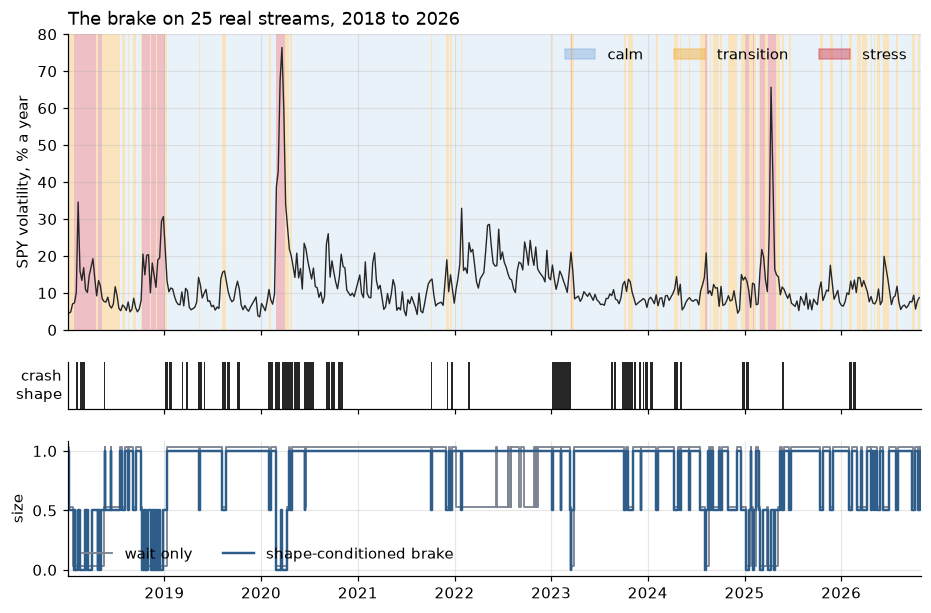

In [14]:
end = pd.Timestamp(REAL["last"])
fig, axes = plt.subplots(3, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"height_ratios": [2.2, 0.35, 1]})
state, _ = runs_to_series(REAL["runs"]["state"], end)
bounds = list(state.index[1:]) + [end]
ax = axes[0]
for a, b, s in zip(state.index, bounds, state.to_numpy()):
    ax.axvspan(a, b, color=STATE_COLORS[int(s)], alpha=0.35 if s else 0.18, lw=0)
ax.plot(weekly_vol.index, weekly_vol, color="0.15", lw=0.9)
ax.set_ylabel("SPY volatility, % a year")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s], alpha=0.5) for s in range(3)]
ax.legend(handles, [STATE_NAMES[s] for s in range(3)], frameon=False, ncol=3, loc="upper right")
ax.set_title("The brake on 25 real streams, 2018 to 2026", loc="left")
crash, _ = runs_to_series(REAL["runs"]["crash"], end)
cb = list(crash.index[1:]) + [end]
for a, b, c in zip(crash.index, cb, crash.to_numpy()):
    if c:
        axes[1].axvspan(a, b, color="0.15", lw=0)
axes[1].set_yticks([])
axes[1].set_ylabel("crash\nshape", rotation=0, ha="right", va="center")
axes[1].grid(False)
for key, label, color, lw in [("sw5", "wait only", BRAKE_COLORS["wait only"], 1.2),
                              ("mult", "shape-conditioned brake", BRAKE_COLORS["shape-conditioned"], 1.6)]:
    s, _ = runs_to_series(REAL["runs"][key], end)
    s = pd.concat([s, pd.Series([s.iloc[-1]], index=[end])])
    axes[2].step(s.index, s.to_numpy() + (0.03 if key == "sw5" else 0), where="post", color=color, lw=lw, label=label)
axes[2].set_yticks([0, 0.5, 1])
axes[2].set_ylabel("size")
axes[2].legend(frameon=False, ncol=2, loc="lower left")
axes[2].set_xlim(state.index[0], end)
plt.show()

The figure shows the brake over the whole real sample. The top panel has SPY's realised volatility over the trailing five sessions, measured from five-minute returns and sampled every Friday, behind the volatility state as shading. The middle strip marks the days in the crash shape. The bottom panel has the size of the wait-only labeler (grey, lifted slightly) and of the shape-conditioned brake (blue).

Stress lines up with the volatility spikes of 2018, March 2020, August 2024 and spring 2025. The release shows up as short half-size steps inside the stress spells, where the wait-only labeler stays at zero. The crash shape comes in patches, often in quiet years too, which is the first sign that it measures co-movement and not danger.

In [15]:
yt = years.copy()
print(yt.to_string(float_format=lambda v: f"{v:.2f}"))
z = REAL["zero_spells"]
print(f"\nsessions at zero, shape-conditioned brake {z['brake'][2]} in {z['brake'][0]} spells (mean {z['brake'][1]} sessions), "
      f"wait only {z['wait only'][2]} in {z['wait only'][0]} spells (mean {z['wait only'][1]} sessions)")
check("the brake spends less than half as many sessions at zero as the wait-only labeler", z["brake"][2] < 0.5 * z["wait only"][2])
check("2018 was almost half stress, 2022 had no stress and full size", years.loc[2018, "stress"] > 0.4
      and years.loc[2022, "stress"] == 0 and years.loc[2022, "mean size brake"] >= 0.99)

      calm  transition  stress  crash shape  mean size brake  mean size wait only  release days
year                                                                                           
2018  0.15        0.40    0.45         0.08             0.46                 0.31            75
2019  0.92        0.08    0.00         0.26             0.96                 0.95             5
2020  0.81        0.09    0.10         0.49             0.85                 0.85             3
2021  0.94        0.06    0.00         0.04             0.97                 0.97             0
2022  0.99        0.01    0.00         0.02             1.00                 0.65             0
2023  0.86        0.13    0.01         0.46             0.93                 0.92             6
2024  0.63        0.35    0.02         0.11             0.81                 0.79             8
2025  0.56        0.28    0.16         0.04             0.73                 0.65            40
2026  0.60        0.40    0.00         0

The yearly table gives the share of sessions in each volatility state and in the crash shape, the mean size of the brake and of the wait-only labeler, and the number of release days, when the brake was above zero while the wait-only labeler was at zero. Most release days fall in 2018 and 2025, the two years with long stress spells. Over the whole sample the brake was at zero for less than half as many sessions as the wait-only labeler, in more and shorter spells.

Two years show how relative the names are. In 2018 almost half the sessions were stress. That refit trained on 376 sessions from 2016 and 2017, one of the calmest stretches on record, so any normal sell-off looked extreme. In 2022, a bear market in which the S&P 500 lost about a quarter, the brake had no stress and almost no transition, and ran at full size all year. Its refit trained on 2020 and 2021, and the refit table below shows why.

In [16]:
rows = []
for v, s in zip(REAL["vol_refits"], REAL["shape_refits"]):
    k = s["mean kappa"]
    rows.append({"refit": v["year"], "training sessions": v["n_train"],
                 "mean v, calm / transition / stress": " / ".join(f"{x:.2f}" for x in v["mean v"]),
                 "training share": " / ".join(f"{x:.2f}" for x in v["shares"]),
                 "mean kappa of the shapes": " / ".join(f"{x:.3f}" for x in k),
                 "crash-shape margin": k[2] - k[1]})
refits = pd.DataFrame(rows).set_index("refit")
print(refits.to_string(float_format=lambda v: f"{v:.3f}"))
close = refits[refits["crash-shape margin"] < 0.005].index.tolist()
check("two refits named the crash shape by a margin below 0.005", len(close) == 2, f"({close})")

       training sessions mean v, calm / transition / stress      training share mean kappa of the shapes  crash-shape margin
refit                                                                                                                       
2018                 376                 0.57 / 0.80 / 1.75  0.48 / 0.49 / 0.03    0.273 / 0.373 / 0.374               0.001
2019                 504                 0.75 / 1.97 / 7.13  0.79 / 0.19 / 0.02    0.282 / 0.374 / 0.504               0.130
2020                 504                 0.80 / 1.98 / 7.13  0.77 / 0.22 / 0.02    0.318 / 0.468 / 0.470               0.002
2021                 504                0.66 / 2.34 / 17.65  0.86 / 0.10 / 0.04    0.342 / 0.449 / 0.494               0.045
2022                 504                0.70 / 9.94 / 28.22  0.95 / 0.03 / 0.02    0.305 / 0.443 / 0.489               0.046
2023                 504                 0.58 / 1.30 / 2.67  0.46 / 0.41 / 0.13    0.295 / 0.415 / 0.475               0.060


The table gives, for each January refit, the mean scaled variance $v$ of the training days in each volatility cluster and their share of the training days, and the mean concentration $\kappa$ of the three shape clusters, with the margin by which the crash shape won its name.

The 2022 refit explains that year. Trained on 2020 and 2021, its transition cluster had a mean $v$ of almost 10 and its stress cluster 28, the scale of the COVID weeks. Only 5% of training days were outside calm, so a grinding bear with $v$ of 2 or 3 stayed calm. The stress label answers the question "is this week like the worst weeks of the last two years", not "is the market stressed".

The last column is the weak point of the shape axis. The crash shape is the cluster with the highest mean $\kappa$, and in 2018 and 2020 the top two clusters differed by 0.001 and 0.002. In those years the name is close to a coin flip. The clustering is done on the whole shape fingerprint, and the naming on a single summary of it, and the two need not agree.

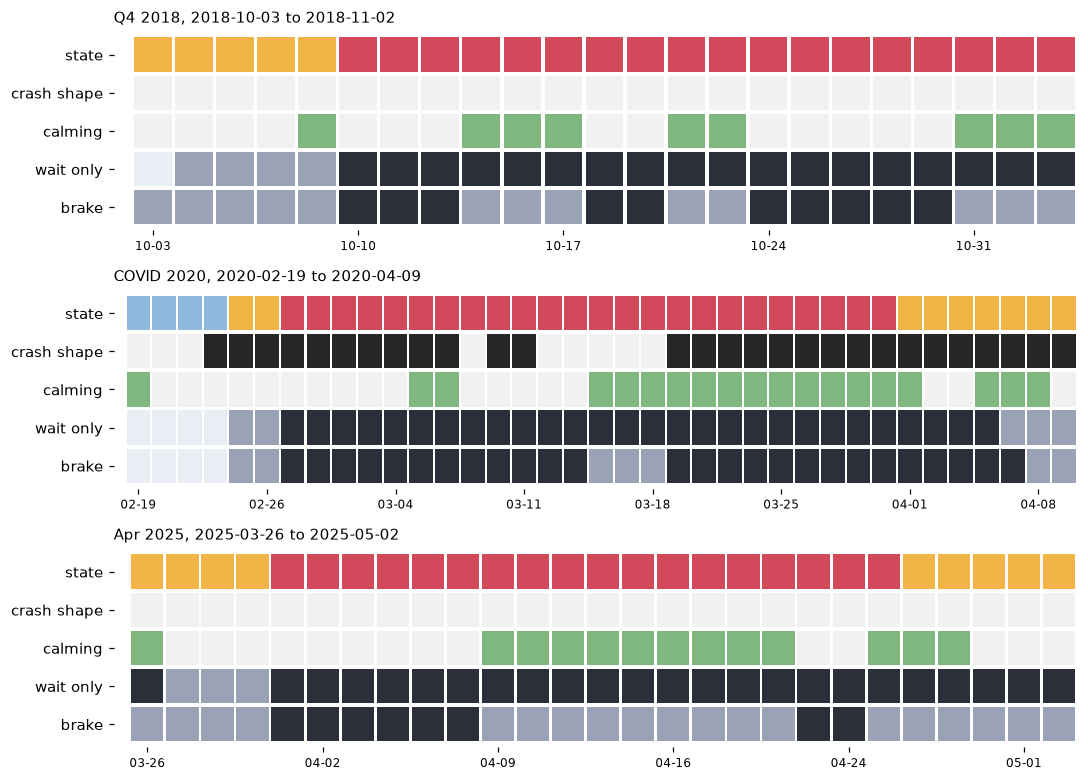

Q4 2018    kappa 0.27 0.32 0.32 0.33 0.34 0.40 0.47 0.50 0.51 0.52 0.52 0.50 0.48 0.49 0.50 0.51 0.49 0.52 0.54 0.54 0.52 0.51 0.48
COVID 2020 kappa 0.41 0.48 0.49 0.51 0.56 0.59 0.64 0.64 0.64 0.66 0.65 0.64 0.63 0.56 0.53 0.52 0.48 0.49 0.51 0.51 0.51 0.52 0.52 0.53 0.52 0.52 0.53 0.52 0.49 0.49 0.48 0.48 0.50 0.50 0.52 0.52 0.48
Apr 2025   kappa 0.38 0.39 0.38 0.43 0.47 0.48 0.47 0.55 0.68 0.68 0.63 0.63 0.62 0.57 0.57 0.53 0.48 0.46 0.45 0.45 0.42 0.42 0.42 0.41 0.41 0.41 0.40


In [17]:
def event_strip(ax, ev, title):
    rows = [("state", lambda c: STATE_COLORS[int(c)]),
            ("crash shape", lambda c: "0.15" if c == "1" else "#F1F1F1"),
            ("calming", lambda c: "#7FB77E" if c == "1" else "#F1F1F1"),
            ("wait only", lambda c: SIZE_COLORS[{"0": 0.0, "5": 0.5, "1": 1.0}[c]]),
            ("brake", lambda c: SIZE_COLORS[{"0": 0.0, "5": 0.5, "1": 1.0}[c]])]
    keys = {"state": "state", "crash shape": "crash", "calming": "calming", "wait only": "wait only", "brake": "brake"}
    n = ev["dates"][2]
    for row, (name, colour) in enumerate(rows):
        for i, c in enumerate(ev[keys[name]]):
            ax.add_patch(plt.Rectangle((i, -row - 0.45), 0.92, 0.9, color=colour(c), lw=0))
    ax.set_xlim(-0.5, n)
    ax.set_ylim(-len(rows) + 0.4, 0.6)
    ax.set_yticks([-r for r in range(len(rows))], [r[0] for r in rows])
    ticks = list(range(0, n, 5))
    ax.set_xticks([t + 0.46 for t in ticks], [ev["tick dates"][t][5:] for t in ticks], fontsize=8)
    ax.grid(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.set_title(title, loc="left", fontsize=10)


fig, axes = plt.subplots(3, 1, figsize=(10, 7.2))
for ax, (name, ev) in zip(axes, REAL["events"].items()):
    event_strip(ax, ev, f"{name}, {ev['dates'][0]} to {ev['dates'][1]}")
fig.tight_layout()
plt.show()
for name, ev in REAL["events"].items():
    print(f"{name:10s} kappa " + " ".join(f"{k:.2f}" for k in ev["kappa"]))

The figure shows three events session by session. The rows are the volatility state (blue calm, yellow transition, red stress), the crash shape (black when on), calming (green when on), and the size of the wait-only labeler and of the brake (dark 0, grey 0.5, light 1). The concentration $\kappa$ of each day is printed below the figure.

#### COVID, February to April 2020

The crash shape was on from 24 February through the first week of March, while the assets fell together, and it held the brake at zero over the bounce of 5 and 6 March, when volatility was briefly calming. The fall of 9 to 12 March followed. That is the case the rule was built for. The shape then switched off on 9 March and from 12 to 18 March. Bonds, gold and the dollar broke away from equities and $\kappa$ fell from about 0.65 to about 0.50, although the 13 equity funds on their own still moved almost as one block, with a first-eigenvalue share near 0.8 in a separate check. So the brake went back to half size on 16 to 18 March, among the worst days of the crash. The market turned a week later, so that re-entry happened to come close to the low, but the rule did not see that coming.

#### Q4 2018

The crash shape was never on, although $\kappa$ rose from 0.27 to above 0.50. This is the refit whose crash shape won its name by 0.001, and the October 2018 days sat nearer another shape cluster. So every calming day released the brake, three times between mid-October and early November, while the fall went on into December.

#### April 2025

$\kappa$ reached 0.68 on 7 and 8 April, higher than on any day of the COVID crash, and the crash shape still stayed off. The fingerprint of those days was closer to a different cluster than to the one with the highest mean $\kappa$. The brake released from 9 April on, the day the market turned, which here helped.

The three events show the same thing from different sides. The crash shape is a cluster of whole fingerprints, named by an average, so it does not track $\kappa$ day by day. When it agreed with the eye it held the brake through a second leg, and when it did not the release acted as a plain release.

In [18]:
ar = pd.DataFrame(REAL["after_release"]).T
ar.columns = ["sessions", "SPY return next 5, %", "SPY volatility next 5, % a year", "worst SPY fall within 10, %",
              "share with a fall below -5% within 10"]
print(ar.to_string(float_format=lambda v: f"{v:.2f}"))
rel, held = ar.loc["released (brake above 0, wait only at 0)"], ar.loc["held (both at 0)"]
check("weeks after a release were calmer than weeks after a held day",
      rel["SPY volatility next 5, % a year"] < 0.6 * held["SPY volatility next 5, % a year"])
check("but at least one release in six came before a fall below -5% within ten sessions",
      rel["share with a fall below -5% within 10"] >= 1 / 6, f"({rel['share with a fall below -5% within 10']:.2f})")

                                          sessions  SPY return next 5, %  SPY volatility next 5, % a year  worst SPY fall within 10, %  share with a fall below -5% within 10
released (brake above 0, wait only at 0)    137.00                  0.29                            18.07                        -2.44                                   0.20
held (both at 0)                            111.00                 -0.65                            37.70                        -5.06                                   0.35
all days                                   2195.00                  0.23                            15.09                        -1.74                                   0.09
check 21 passed: weeks after a release were calmer than weeks after a held day 
check 22 passed: but at least one release in six came before a fall below -5% within ten sessions (0.20)


The table compares the days on which the brake released, when it was above zero and the wait-only labeler at zero, with the days on which both were at zero, and with all days. For each it gives SPY's mean close-to-close log return and annualised volatility over the next five sessions, the mean of the worst cumulative return within the next ten sessions, and the share of days on which that worst return was below $-5\%$.

The release picked the calmer side of the stress spells. The weeks after a release had about half the volatility of the weeks after a held day, and on average a smaller worst fall. But about one release in five still came before a fall of more than 5% within ten sessions, against about one in three held days. The release thins out the danger, it does not remove it.

In [19]:
st = pd.DataFrame(REAL["stability"]).set_index(["directions", "seed"])
print(st.to_string(float_format=lambda v: f"{v:.3f}"))
sob, rnd = st.loc["sobol"], st.loc["random"]
check("under other Sobol scrambles the stress days overlap by at least 94%", sob["stress Jaccard"].min() >= 0.94)
check("the crash-shape days overlap by as little as 63%", 0.6 <= sob["crash shape Jaccard"].min() <= 0.66,
      f"(min {sob['crash shape Jaccard'].min():.2f})")
check("random directions can move the crash shape much more", rnd["crash shape Jaccard"].min() < 0.5)

                 state agree  stress Jaccard  crash shape Jaccard  multiplier agree  mean multiplier
directions seed                                                                                     
sobol      1           0.911           0.973                0.808             0.901            0.792
           2           0.901           0.946                0.908             0.903            0.802
           3           0.909           0.962                0.873             0.910            0.798
           4           0.908           0.978                0.730             0.900            0.793
           5           0.908           0.962                0.780             0.908            0.800
           6           0.911           0.948                0.901             0.913            0.795
           7           0.906           0.957                0.630             0.872            0.782
           8           0.910           0.968                0.881             0.907        

The table reruns the whole brake from 2018 with nine other Sobol scrambles and with three sets of 256 random directions, and compares each with the original. The columns are the share of sessions with the same volatility state, the overlap of the stress sessions and of the crash-shape sessions (intersection over union), the share of sessions with the same size and the mean size.

The volatility state barely depends on the directions. Its stress days overlap by 95% to 98% under every Sobol scramble. The crash shape is far less stable, with overlaps from 63% to 91%, and with random directions it can fall to 39%. This matches section 3, where evenly spread directions removed most of the luck from the volatility part and much less from the shape part. Three random sets are too few to say that Sobol directions make the labels more stable on real data. Two of them agree with the original more closely than any other Sobol scramble, and the third moves the crash shape far more. Between 87% and 91% of sessions get the same size under another Sobol scramble, and the sessions that differ are exactly the release decisions inside stress spells, where the brake matters most.

## 9. Run it on your own data

`regime_brake` takes a DataFrame of intraday log returns with a two-level index (date, slot within the day) and one column per asset. Every day must have the same number of slots, so drop half-day sessions first. It refits both sets of clusters on the first day of each year and returns one row per labelled day with the volatility state, the crash shape, calming, the concentration and the size.

The cell below runs it on a synthetic legs history with dates attached and then checks for look-ahead. The returns after a cut-off date are tripled and the brake is rerun, and every label and size up to the cut-off must stay the same. The concentration may differ in the last digits, since the eigenvalue routine can sum in a different order from run to run.

In [20]:
def regime_brake(returns, n_dir=256, window=5, k=3, train_days=504, min_train=250, scale_days=252,
                 min_scale_days=120, wait=5, seed=0):
    # Walk-forward volatility state, crash shape, calming and size from a DataFrame of intraday returns.
    dates = returns.index.get_level_values(0).unique()
    X = returns.to_numpy().reshape(len(dates), -1, returns.shape[1])
    Z = scale_streams(X, scale_days, min_scale_days)
    dirs = sobol_directions(n_dir, X.shape[2], seed)
    F, v = vol_fingerprints(Z, dirs, window)
    S, kappa = shape_fingerprints(X, dirs, window)
    ok = np.isfinite(F).all(axis=1)
    S[~ok] = np.nan
    state, shape = np.full(len(dates), np.nan), np.full(len(dates), np.nan)
    for year in sorted(set(dates.year)):
        first = np.flatnonzero(dates.year == year)[0]
        past = np.flatnonzero(ok[:first])[-train_days:]
        if len(past) < min_train:
            continue
        now = np.flatnonzero((dates.year == year) & ok)
        km, rank, _ = fit_ranked(F[past], v[past], k)
        kms, rank_s, _ = fit_ranked(S[past], kappa[past], k)
        state[now], shape[now] = rank[km.predict(F[now])], rank_s[kms.predict(S[now])]
    calm = calming(daily_variance(Z))
    on = np.isfinite(state)
    out = pd.DataFrame({"state": state[on].astype(int), "crash_shape": shape[on] == k - 1, "calming": calm[on],
                        "kappa": kappa[on]}, index=dates[on])
    out["name"] = out.state.map(STATE_NAMES)
    out["size"] = brake(out.state, out.crash_shape, out.calming, wait=wait)
    return out


X = simulate("legs", np.random.default_rng([41, 0]))
dates = pd.bdate_range("2019-01-01", periods=DAYS)
index = pd.MultiIndex.from_product([dates, range(STEPS)], names=["date", "slot"])
returns = pd.DataFrame(X.reshape(-1, N_ASSETS), index=index, columns=[f"asset_{j}" for j in range(N_ASSETS)])

t_start = time.time()
out = regime_brake(returns, n_dir=64)
print(f"labelled {len(out)} days in {time.time() - t_start:.0f} s")
print(out.groupby(out.index.year).agg(stress=("state", lambda s: np.mean(s == 2)), crash_shape=("crash_shape", "mean"),
                                      mean_size=("size", "mean")).round(3).to_string())

cut = pd.Timestamp("2022-06-30")
changed = returns.copy()
changed.loc[changed.index.get_level_values("date") > cut] *= 3
out2 = regime_brake(changed, n_dir=64)
a, b = out.loc[:cut], out2.loc[:cut]
same = a.drop(columns=["kappa", "name"]).equals(b.drop(columns=["kappa", "name"]))
kappa_gap = float((a.kappa - b.kappa).abs().max())
check("no look-ahead, changing later data leaves every earlier label and size unchanged", same and kappa_gap < 1e-12,
      f"({len(a)} days compared, largest concentration difference {kappa_gap:.0e})")

labelled 577 days in 3 s
      stress  crash_shape  mean_size
date                                
2021   0.000        0.000      0.994
2022   0.073        0.092      0.504
2023   0.000        0.018      0.616


check 26 passed: no look-ahead, changing later data leaves every earlier label and size unchanged (390 days compared, largest concentration difference 6e-16)


To use real data, load your bars, compute log returns per five-minute slot, pivot to one column per asset and call `regime_brake(returns)`. Use `n_dir` a power of two. The size is decided at the close with that day's bars, so acting on it the next day is a different rule, and the release, which reacts within a day, is the part that suffers most from a delay.

## 10. Limits

- Every real-data result here is in-sample. The settings were chosen in a backtest on 2008 to 2025, so the real test is data from 2026 on.
- Stress is relative to the last two years. After a crash in the training window, only crash-sized weeks count as stress, so in 2022 the brake ran at full size through a bear market. A threshold fixed once in plain units would be stable, at the cost of no longer adapting.
- The crash shape is a cluster named by its mean concentration. Twice the name was won by less than 0.002, and it moves with the directions far more than the volatility state does. A direct rule on $\kappa$, or on the concentration of the equity block alone, with a threshold fixed once, would remove both the naming step and most of the direction dependence.
- The release is a bet that a calming shock will not come back. It is right after V-shaped shocks and wrong in a crash with a pause in it, unless the crash shape is on in the pause. In COVID it held through the first pause and released into the second. In Q4 2018 it released three times while the fall went on.
- Twenty-five streams with 13 equity funds give the equity block a large weight in both fingerprints. Concentration therefore mostly measures how much equities move together, and a cross-asset flip such as the stock–bond flip of the synthetic market is seen by neither axis.
- Five-session windows lag. The first day of a crash can still be calm, and the volatility state needs a few bad days before it reaches stress.

## References

- Agueh, M. and Carlier, G. (2011). Barycenters in the Wasserstein space. SIAM Journal on Mathematical Analysis 43(2), 904–924.
- Bonneel, N., Rabin, J., Peyré, G. and Pfister, H. (2015). Sliced and Radon Wasserstein barycenters of measures. Journal of Mathematical Imaging and Vision 51, 22–45.
- Dick, J. and Pillichshammer, F. (2010). Digital Nets and Sequences. Discrepancy Theory and Quasi-Monte Carlo Integration. Cambridge University Press.
- Horvath, B., Issa, Z. and Muguruza, A. (2021). Clustering market regimes using the Wasserstein distance. arXiv 2110.11848.
- Joe, S. and Kuo, F. Y. (2008). Constructing Sobol sequences with better two-dimensional projections. SIAM Journal on Scientific Computing 30(5), 2635–2654.
- Kritzman, M., Li, Y., Page, S. and Rigobon, R. (2011). Principal components as a measure of systemic risk. Journal of Portfolio Management 37(4), 112–126.
- Nguyen, K., Bariletto, N. and Ho, N. (2024). Quasi-Monte Carlo for 3D sliced Wasserstein. International Conference on Learning Representations.
- Owen, A. B. (1995). Randomly permuted (t, m, s)-nets and (t, s)-sequences. In Monte Carlo and Quasi-Monte Carlo Methods in Scientific Computing, Lecture Notes in Statistics 106, 299–317.
- Peyré, G. and Cuturi, M. (2019). Computational optimal transport. Foundations and Trends in Machine Learning 11(5–6), 355–607.
- Sobol', I. M. (1967). On the distribution of points in a cube and the approximate evaluation of integrals. USSR Computational Mathematics and Mathematical Physics 7(4), 86–112.

In [21]:
print(f"{len(CHECKS)} checks passed in {time.time() - T0:.0f} s")

26 checks passed in 161 s
